<a href="https://colab.research.google.com/github/Asvelasquez/PROCESAMIENTO-DE-LENGUAJE-NATURAL/blob/main/proyecto_youtube.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Estadisticas de YouTube, avances I, II y III

La idea del proyecto es ver si con los comentarios de un video de YouTube podemos estimar que tan bien le va
(vistas, likes, engagement), y armar todo pensando en buenas practicas de Mlops.

Este notebook genera todos los numeros, tablas y graficas que usamos en el informe, las partes son:

0. Configuracion y carga de datos
1. De donde salen los datos y como se ven
2. Calidad de los datos y si son suficientes
3. Limpieza y creacion de variables
4. Analisis estadisticos
5. Modelo A: clasificador de sentimiento
6. Modelo B: prediccion del desempeno del video
7. Guardar modelos, metricas y un ejemplo de monitoreo
8. Traer mas datos con la API de YouTube (en revision, esta apagada)
9. Avances III: iteracion del modelo, con transformers, embeddings, stacking y registro de experimentos en MLflow


## 0. Configuracion

Fijamos una semilla para que cada vez que se corra salgan los mismos resultados

In [ ]:
import json, hashlib, html, warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from sklearn.model_selection import (StratifiedGroupKFold, GroupShuffleSplit, KFold, train_test_split,
                                     cross_validate, cross_val_predict, GridSearchCV, learning_curve, StratifiedKFold)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import (VotingRegressor, RandomForestRegressor, HistGradientBoostingRegressor,
                              HistGradientBoostingClassifier)
from sklearn.metrics import (f1_score, accuracy_score, classification_report, confusion_matrix,
                             r2_score, mean_absolute_error, mean_squared_error)
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)

DATA_DIR = Path("data")
FIG_DIR = Path("figuras")
OUT_DIR = Path("resultados")
for carpeta in (DATA_DIR, FIG_DIR, OUT_DIR):
    carpeta.mkdir(exist_ok=True)

# colores: azul positivo, gris neutro, rojo negativo
AZUL, ROJO, GRIS, NARANJA, AQUA = "#2a78d6", "#e34948", "#8a8985", "#eb6834", "#1baf7a"
TINTA, TINTA2 = "#0b0b0b", "#52514e"
CMAP_DIV = LinearSegmentedColormap.from_list("div", [ROJO, "#f0efec", AZUL])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.facecolor": "white",
})

RESULTADOS = {}  # aqui vamos guardando los numeros que van al informe

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    plt.show()

def a_nativo(x):
    # json no acepta tipos de numpy, entonces los pasamos a tipos normales de python
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, np.floating):
        return float(x)
    if isinstance(x, dict):
        return {k: a_nativo(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [a_nativo(v) for v in x]
    return x

def registrar(clave, valor):
    RESULTADOS[clave] = a_nativo(valor)

### 0.1 Carga de los datos

Primero mira si los csv ya estan en data/ si no estan, intenta bajarlos de Kaggle con kagglehub y si eso
falla pide subirlos a mano sirven los .zip que se descargan de Kaggle

In [ ]:
ARCHIVOS = ["videos-stats.csv", "comments.csv"]

def obtener_datos():
    if all((DATA_DIR / f).exists() for f in ARCHIVOS):
        return "carpeta data/"
    try:
        import kagglehub, shutil
        ruta = Path(kagglehub.dataset_download("advaypatil/youtube-statistics"))
        for f in ARCHIVOS:
            shutil.copy(ruta / f, DATA_DIR / f)
        return "Kaggle (kagglehub)"
    except Exception as e:
        print("No se pudo con kagglehub:", e)
    # si llegamos aca toca subir los archivos (solo funciona dentro de Colab)
    from google.colab import files
    import zipfile, io
    print("Sube videos-stats.csv y comments.csv (o los zip de Kaggle)")
    for nombre, contenido in files.upload().items():
        if nombre.endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(contenido)).extractall(DATA_DIR)
        else:
            (DATA_DIR / nombre).write_bytes(contenido)
    return "subida manual"

print("Datos cargados desde:", obtener_datos())
videos_raw = pd.read_csv(DATA_DIR / "videos-stats.csv", index_col=0)
comentarios_raw = pd.read_csv(DATA_DIR / "comments.csv", index_col=0)

# el hash sirve para saber exactamente que version de los datos usamos
def hash_archivo(ruta):
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()[:12]

registrar("hash_crudo", {f: hash_archivo(DATA_DIR / f) for f in ARCHIVOS})
print(RESULTADOS["hash_crudo"])

100%|██████████| 1.64M/1.64M [00:00<00:00, 81.5MB/s]

Extracting files...
Datos cargados desde: Kaggle (kagglehub)


{'videos-stats.csv': 'eecaf9f68ee5', 'comments.csv': '37aceb72fa3e'}


## 1. De donde salen los datos y como se ven

Se uso el dataset youTube statistics de Kaggle  para 41 palabras de busqueda (tech, news, finance, gaming...) se tomaron unos 50 videos de los primeros resultados,con sus estadisticas y sus 10 comentarios mas relevantes, cada comentario trae una etiqueta de sentimiento (0 negativo, 1 neutro, 2 positivo)

In [ ]:
print("videos-stats.csv:", videos_raw.shape)
display(videos_raw.head(3))
print("comments.csv:", comentarios_raw.shape)
display(comentarios_raw.head(3))

videos-stats.csv: (1881, 7)


,Title,Video ID,Published At,Keyword,Likes,Comments,Views
0,Apple Pay Is Killing the Physical Wallet After...,wAZZ-UWGVHI,2022-08-23,tech,3407.0,672.0,135612.0
1,The most EXPENSIVE thing I own.,b3x28s61q3c,2022-08-24,tech,76779.0,4306.0,1758063.0
2,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,tech,63825.0,3338.0,1564007.0


comments.csv: (18409, 4)


,Video ID,Comment,Likes,Sentiment
0,wAZZ-UWGVHI,Let's not forget that Apple Pay in 2014 requir...,95.0,1.0
1,wAZZ-UWGVHI,Here in NZ 50% of retailers don’t even have co...,19.0,0.0
2,wAZZ-UWGVHI,I will forever acknowledge this channel with t...,161.0,2.0


In [ ]:
diccionario = pd.DataFrame([
    ["videos-stats", "Title", "texto", "Titulo del video (trae cosas como &#39; en vez de comillas)"],
    ["videos-stats", "Video ID", "texto", "Id del video, sirve para unir con los comentarios"],
    ["videos-stats", "Published At", "fecha", "Fecha de publicacion"],
    ["videos-stats", "Keyword", "categoria", "Palabra de busqueda con la que salio el video (41 en total)"],
    ["videos-stats", "Likes", "numero", "Likes del video (-1 quiere decir que estan ocultos)"],
    ["videos-stats", "Comments", "numero", "Cantidad de comentarios (-1 si estan desactivados)"],
    ["videos-stats", "Views", "numero", "Vistas al momento de sacar los datos"],
    ["comments", "Video ID", "texto", "Video al que pertenece el comentario"],
    ["comments", "Comment", "texto", "El comentario (top 10 por relevancia)"],
    ["comments", "Likes", "numero", "Likes que tuvo el comentario"],
    ["comments", "Sentiment", "0, 1, 2", "Etiqueta de sentimiento que trae el dataset"],
], columns=["Tabla", "Variable", "Tipo", "Que es"])
display(diccionario)

,Tabla,Variable,Tipo,Que es
0,videos-stats,Title,texto,Titulo del video (trae cosas como &#39; en vez...
1,videos-stats,Video ID,texto,"Id del video, sirve para unir con los comentarios"
2,videos-stats,Published At,fecha,Fecha de publicacion
3,videos-stats,Keyword,categoria,Palabra de busqueda con la que salio el video ...
4,videos-stats,Likes,numero,Likes del video (-1 quiere decir que estan ocu...
5,videos-stats,Comments,numero,Cantidad de comentarios (-1 si estan desactiva...
6,videos-stats,Views,numero,Vistas al momento de sacar los datos
7,comments,Video ID,texto,Video al que pertenece el comentario
8,comments,Comment,texto,El comentario (top 10 por relevancia)
9,comments,Likes,numero,Likes que tuvo el comentario


## 2. Calidad de los datos

se revisaron varias cosas datos que faltan, valores raros como los -1, duplicados, videos repetidos con valores
distintos, sesgos de la muestra y que tan confiable es la etiqueta de sentimiento

In [ ]:
v, c = videos_raw.copy(), comentarios_raw.copy()
calidad = {}
calidad["videos_filas"] = len(v)
calidad["videos_unicos"] = v["Video ID"].nunique()
calidad["videos_nulos_views"] = int(v["Views"].isna().sum())
calidad["videos_likes_neg"] = int((v["Likes"] < 0).sum())
calidad["videos_comments_neg"] = int((v["Comments"] < 0).sum())

dup = v[v["Video ID"].duplicated(keep=False)]
calidad["videos_duplicados"] = int(v["Video ID"].duplicated().sum())
# videos que aparecen dos veces pero con vistas diferentes
calidad["dup_views_inconsistentes"] = int(dup.groupby("Video ID")["Views"].nunique().gt(1).sum())
calidad["titulos_con_html"] = int(v["Title"].str.contains("&#|&amp;|&quot;").sum())

calidad["comentarios_filas"] = len(c)
calidad["comentarios_nulos"] = int(c["Comment"].isna().sum())
calidad["comentarios_duplicados"] = int(c.duplicated(["Video ID", "Comment"]).sum())

# porcentaje de comentarios escritos mayormente en otros alfabetos (arabe, hindi, coreano...)
def proporcion_no_latina(texto):
    raros = sum(ord(ch) > 127 and not (0x2000 <= ord(ch) <= 0x206F) for ch in texto)
    return raros / max(len(texto), 1)

no_latinos = c["Comment"].dropna().map(proporcion_no_latina)
calidad["pct_comentarios_no_latinos"] = round(100 * (no_latinos > 0.3).mean(), 2)

por_video = c.groupby("Video ID").size()
calidad["comentarios_por_video_mediana"] = float(por_video.median())
calidad["videos_menos_de_10_comentarios"] = int((por_video < 10).sum())
calidad["pct_sentimiento"] = (c["Sentiment"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict()
calidad["pct_videos_2022"] = round(100 * (pd.to_datetime(v["Published At"]).dt.year == 2022).mean(), 1)
registrar("calidad", calidad)
pd.Series(calidad, dtype=object).to_frame("valor")

,valor
videos_filas,1881
videos_unicos,1869
videos_nulos_views,2
videos_likes_neg,7
videos_comments_neg,2
videos_duplicados,12
dup_views_inconsistentes,4
titulos_con_html,344
comentarios_filas,18409
comentarios_nulos,1


Lo mas curioso es que hay videos repetidos salen en dos keywords y no siempre tienen las mismas vistas, eso quiere decir que los datos no se sacaron todos al mismo tiempo, los -1 tampoco son ceros, son datos ocultos, asi que hay
que tratarlos como faltantes

In [ ]:
print("Ejemplo: el mismo video con datos distintos")
display(dup.sort_values("Video ID")[["Video ID", "Keyword", "Views", "Likes"]].head(8))

Ejemplo: el mismo video con datos distintos


,Video ID,Keyword,Views,Likes
1714,2FYvHn12pOQ,movies,1541874.0,-1.0
1055,2FYvHn12pOQ,reaction,405791.0,29728.0
2,4mgePWWCAmA,tech,1564007.0,63825.0
88,4mgePWWCAmA,gaming,1564007.0,63825.0
1501,5q87K1WaoFI,computer science,1407319.0,42940.0
1832,5q87K1WaoFI,machine learning,906372.0,15137.0
1762,7eh4d6sabA0,data science,295344.0,7555.0
1835,7eh4d6sabA0,machine learning,32605.0,1237.0


### 2.1 Sesgos de la muestra

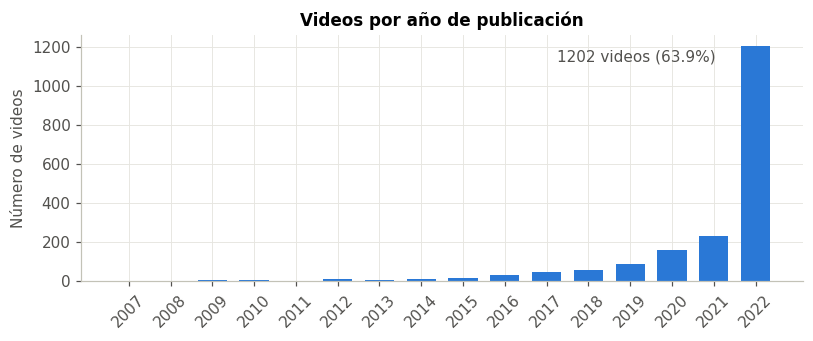

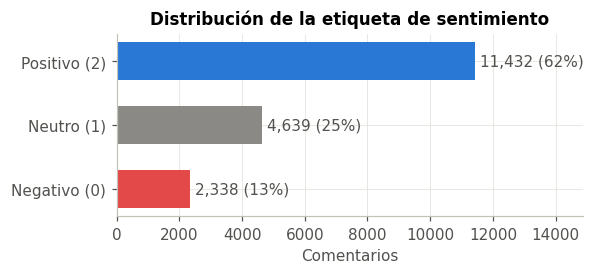

In [ ]:
anios = pd.to_datetime(v["Published At"]).dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(anios.index.astype(str), anios.values, color=AZUL, width=0.7)
ax.set_title("Videos por año de publicación")
ax.set_ylabel("Número de videos")
ax.tick_params(axis="x", rotation=45)
ax.annotate(f"{anios.get(2022, 0)} videos ({calidad['pct_videos_2022']}%)", xy=(len(anios) - 1, anios.iloc[-1]),
            xytext=(-130, -10), textcoords="offset points", color=TINTA2)
guardar_fig("fig01_videos_por_anio")

sent = c["Sentiment"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 2.6))
ax.barh(["Negativo (0)", "Neutro (1)", "Positivo (2)"], sent.values, color=[ROJO, GRIS, AZUL], height=0.6)
for i, val in enumerate(sent.values):
    ax.text(val + 150, i, f"{val:,} ({100 * val / sent.sum():.0f}%)", va="center", color=TINTA2)
ax.set_title("Distribución de la etiqueta de sentimiento")
ax.set_xlim(0, sent.max() * 1.3)
ax.set_xlabel("Comentarios")
guardar_fig("fig02_sentimiento")

### 2.2 Alcanzan los datos

Para no quedarnos solo en la opinion usamos dos cosas,  la primera es un calculo de potencia: con cierta cantidad de
videos, cual es la correlacion mas pequena que alcanzamos a detectar, la segunda son las curvas de aprendizaje
(en las partes 5 y 6): si el modelo sigue mejorando cuando le damos mas datos, es porque nos faltan datos

In [ ]:
def r_minima_detectable(n, alfa=0.05, potencia=0.80):
    # formula con la transformacion z de Fisher
    z = stats.norm.ppf(1 - alfa / 2) + stats.norm.ppf(potencia)
    return np.tanh(z / np.sqrt(n - 3))

n_videos = v["Video ID"].nunique()
potencia = {f"n={n}": round(r_minima_detectable(n), 3) for n in [50, 200, n_videos, 5000, 20000]}
registrar("potencia_r_min", potencia)
print("Correlacion minima que se puede detectar:", potencia)

n_por_keyword = v.groupby("Keyword")["Video ID"].nunique().median()
registrar("r_min_por_keyword", round(r_minima_detectable(int(n_por_keyword)), 3))
print(f"Con los videos de una sola keyword (n={int(n_por_keyword)}): r minima = {RESULTADOS['r_min_por_keyword']}")

Correlacion minima que se puede detectar: {'n=50': np.float64(0.387), 'n=200': np.float64(0.197), 'n=1869': np.float64(0.065), 'n=5000': np.float64(0.04), 'n=20000': np.float64(0.02)}
Con los videos de una sola keyword (n=48): r minima = 0.395


## 3. Limpieza y creacion de variables

Lo que se hizp:
1. Quitar los 2 videos que no tienen estadisticas
2. Cambiar los -1 por NaN
3. En los videos repetidos dejar el registro con mas vistas (el mas reciente)
4. Arreglar los titulos que traen codigos HTML
5. Quitar comentarios vacios y repetidos

despues se juntanron los comentarios por video, porque lo que queremos predecir es algo del video

In [ ]:
v = videos_raw.dropna(subset=["Views"]).copy()
for col in ["Likes", "Comments"]:
    v.loc[v[col] < 0, col] = np.nan
v = v.sort_values("Views", ascending=False).drop_duplicates("Video ID").reset_index(drop=True)
v["Title"] = v["Title"].map(html.unescape)
v["Published At"] = pd.to_datetime(v["Published At"])

c = comentarios_raw.dropna(subset=["Comment"]).drop_duplicates(["Video ID", "Comment"]).copy()
c = c[c["Video ID"].isin(v["Video ID"])].reset_index(drop=True)
c["Sentiment"] = c["Sentiment"].astype(int)
print("Videos:", v.shape, "| Comentarios:", c.shape)
registrar("tamano_limpio", {"videos": len(v), "comentarios": len(c)})

Videos: (1867, 7) | Comentarios: (18139, 4)


In [ ]:
FECHA_CORTE = pd.Timestamp("2022-08-26")  # mas o menos cuando se sacaron los datos

# variables por comentario
c["polaridad"] = c["Sentiment"] - 1  # queda en -1, 0 y 1
c["largo"] = c["Comment"].str.len()
c["log_likes_com"] = np.log1p(c["Likes"])
c["es_pregunta"] = c["Comment"].str.contains(r"\?")
c["exclamacion"] = c["Comment"].str.contains("!")

# ahora agrupamos por video
g = c.groupby("Video ID")
sent_top = c.loc[g["Likes"].idxmax(), ["Video ID", "polaridad"]].set_index("Video ID")["polaridad"]
# sentimiento ponderado: los comentarios con mas likes pesan mas
suma_ponderada = (c["polaridad"] * c["log_likes_com"]).groupby(c["Video ID"]).sum()
suma_pesos = g["log_likes_com"].sum().replace(0, np.nan)

agg = pd.DataFrame({
    "sent_media": g["polaridad"].mean(),
    "sent_std": g["polaridad"].std().fillna(0),
    "pct_neg": g["Sentiment"].apply(lambda s: (s == 0).mean()),
    "pct_pos": g["Sentiment"].apply(lambda s: (s == 2).mean()),
    "sent_ponderado": suma_ponderada / suma_pesos,
    "sent_top": sent_top,
    "largo_medio": g["largo"].mean(),
    "pct_preguntas": g["es_pregunta"].mean(),
    "pct_exclamacion": g["exclamacion"].mean(),
    "n_coment_muestra": g.size(),
    "log_likes_coment": np.log10(g["Likes"].sum() + 1),
    "log_likes_coment_max": np.log10(g["Likes"].max() + 1),
    "texto_comentarios": g["Comment"].apply(" ".join),
})
agg["sent_ponderado"] = agg["sent_ponderado"].fillna(agg["sent_media"])

df = v.merge(agg, left_on="Video ID", right_index=True, how="inner")

# variables del video
df["edad_dias"] = (FECHA_CORTE - df["Published At"]).dt.days.clip(lower=1)
df["log_edad"] = np.log10(df["edad_dias"])
df["largo_titulo"] = df["Title"].str.len()
df["titulo_pregunta"] = df["Title"].str.contains(r"\?").astype(int)
df["titulo_numero"] = df["Title"].str.contains(r"\d").astype(int)
df["dia_semana"] = df["Published At"].dt.dayofweek

# lo que queremos predecir
df["log_views"] = np.log10(df["Views"] + 1)
df["log_likes"] = np.log10(df["Likes"] + 1)
df["engagement"] = df["Likes"] / df["Views"]
df["log_engagement"] = np.log10((df["Likes"] + 1) / (df["Views"] + 1))
df["views_por_dia"] = df["Views"] / df["edad_dias"]
# 1 si al video le fue mejor que a la mitad de los videos de su misma keyword
mediana_kw = df.groupby("Keyword")["log_views"].transform("median")
df["alto_desempeno"] = (df["log_views"] > mediana_kw).astype(int)
print(df.shape)
df.head(3)

(1867, 32)


,Title,Video ID,Published At,Keyword,Likes,Comments,Views,sent_media,sent_std,pct_neg,...,largo_titulo,titulo_pregunta,titulo_numero,dia_semana,log_views,log_likes,engagement,log_engagement,views_por_dia,alto_desempeno
0,El Chombo - Dame Tu Cosita feat. Cutty Ranks (...,FzG4uDgje3M,2018-04-05,google,16445558.0,732818.0,4.034122e+09,0.6,0.516398,0.0,...,75,0,0,3,9.605749,7.216049,0.004077,-2.389700,2.515039e+06,1
1,Martin Garrix - Animals (Official Video),gCYcHz2k5x0,2013-06-17,animals,11025176.0,335455.0,1.582263e+09,0.7,0.483046,0.0,...,40,0,0,0,9.199279,7.042386,0.006968,-2.156893,4.713324e+05,1
2,The Weeknd - Save Your Tears (Official Music V...,XXYlFuWEuKI,2021-01-05,music,6823113.0,270948.0,9.154571e+08,0.1,0.737865,0.2,...,51,0,0,1,8.961638,6.833983,0.007453,-2.127655,1.530865e+06,1


## 4. Analisis estadisticos

Como las vistas tienen valores extremos (unos pocos videos con muchisimas vistas), se usan  pruebas que no suponen datos normales, ademas de los p-valores miramos el tamano del efecto, porque con casi 2.000 videos casi todo sale significativo y lo que importa es que tan grande es la diferencia

### 4.1 Como se distribuyen las vistas

{'asimetria_views': 29.4613, 'asimetria_log_views': 0.0492, 'gini_views': 0.9197, 'pct_vistas_top10pct': 88.5617, 'ks_lognormal_D': 0.0223, 'ks_lognormal_p': 0.3088, 'mediana_views': 591721.0, 'media_views': 11654498.5474}


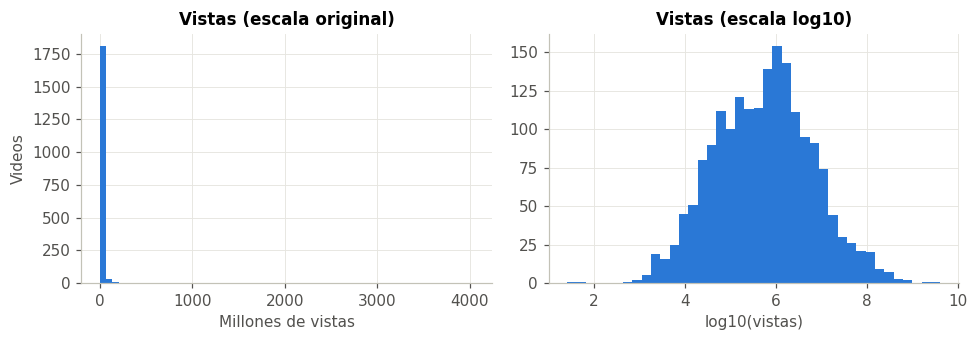

In [ ]:
views = df["Views"].values

def gini(x):
    x = np.sort(x)
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

forma, loc, escala = stats.lognorm.fit(views, floc=0)
ks_lognorm = stats.kstest(views, "lognorm", args=(forma, loc, escala))
top10 = np.sort(views)[::-1][: int(0.1 * len(views))].sum() / views.sum()
dist = {"asimetria_views": stats.skew(views), "asimetria_log_views": stats.skew(df["log_views"]),
        "gini_views": gini(views), "pct_vistas_top10pct": 100 * top10,
        "ks_lognormal_D": ks_lognorm.statistic, "ks_lognormal_p": ks_lognorm.pvalue,
        "mediana_views": np.median(views), "media_views": views.mean()}
registrar("distribucion", {k: round(float(x), 4) for k, x in dist.items()})
print(RESULTADOS["distribucion"])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(views / 1e6, bins=60, color=AZUL)
axes[0].set_title("Vistas (escala original)")
axes[0].set_xlabel("Millones de vistas")
axes[0].set_ylabel("Videos")
axes[1].hist(df["log_views"], bins=40, color=AZUL)
axes[1].set_title("Vistas (escala log10)")
axes[1].set_xlabel("log10(vistas)")
guardar_fig("fig03_distribucion_vistas")

### 4.2 Correlaciones de Spearman
Usamos Spearman porque trabaja con el orden de los datos y no se deja afectar tanto por los videos virales.

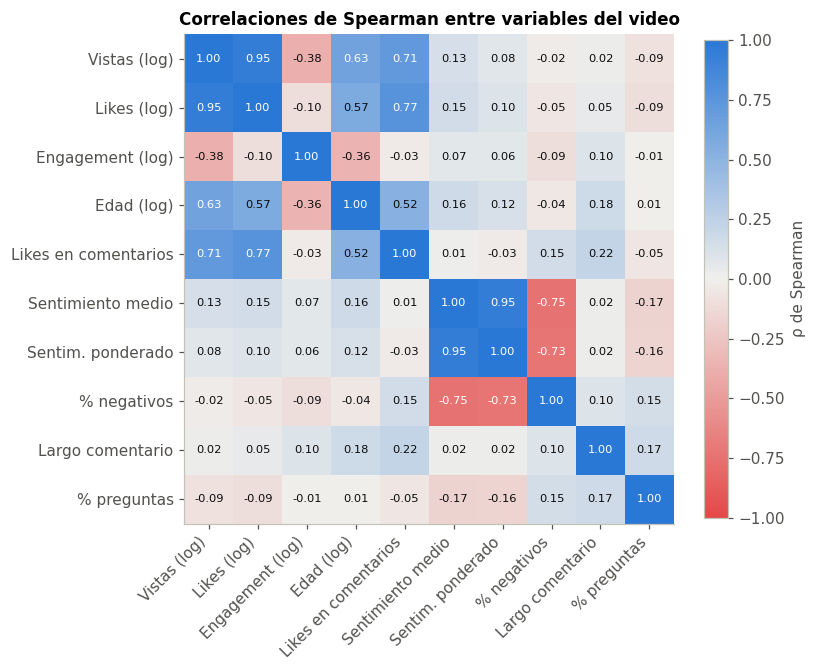

In [ ]:
cols_corr = {"log_views": "Vistas (log)", "log_likes": "Likes (log)", "log_engagement": "Engagement (log)",
             "log_edad": "Edad (log)", "log_likes_coment": "Likes en comentarios",
             "sent_media": "Sentimiento medio", "sent_ponderado": "Sentim. ponderado",
             "pct_neg": "% negativos", "largo_medio": "Largo comentario", "pct_preguntas": "% preguntas"}
corr = df[list(cols_corr)].corr(method="spearman").rename(index=cols_corr, columns=cols_corr)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr.values, cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        color = "white" if abs(corr.values[i, j]) > 0.6 else TINTA
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=color)
plt.colorbar(im, ax=ax, fraction=0.04, label="ρ de Spearman")
ax.set_title("Correlaciones de Spearman entre variables del video")
guardar_fig("fig04_correlaciones")
registrar("spearman_con_views", corr["Vistas (log)"].round(3).to_dict())
registrar("spearman_con_engagement", corr["Engagement (log)"].round(3).to_dict())

### 4.3 El tema influye en las vistas
Kruskal-Wallis es como un ANOVA pero sin suponer normalidad, el epsilon cuadrado nos dice que tanto pesa el tema

{'H': 587.2, 'p': 2.104090322665035e-98, 'epsilon2': 0.3, 'H_engagement': 717.8, 'epsilon2_engagement': 0.373}


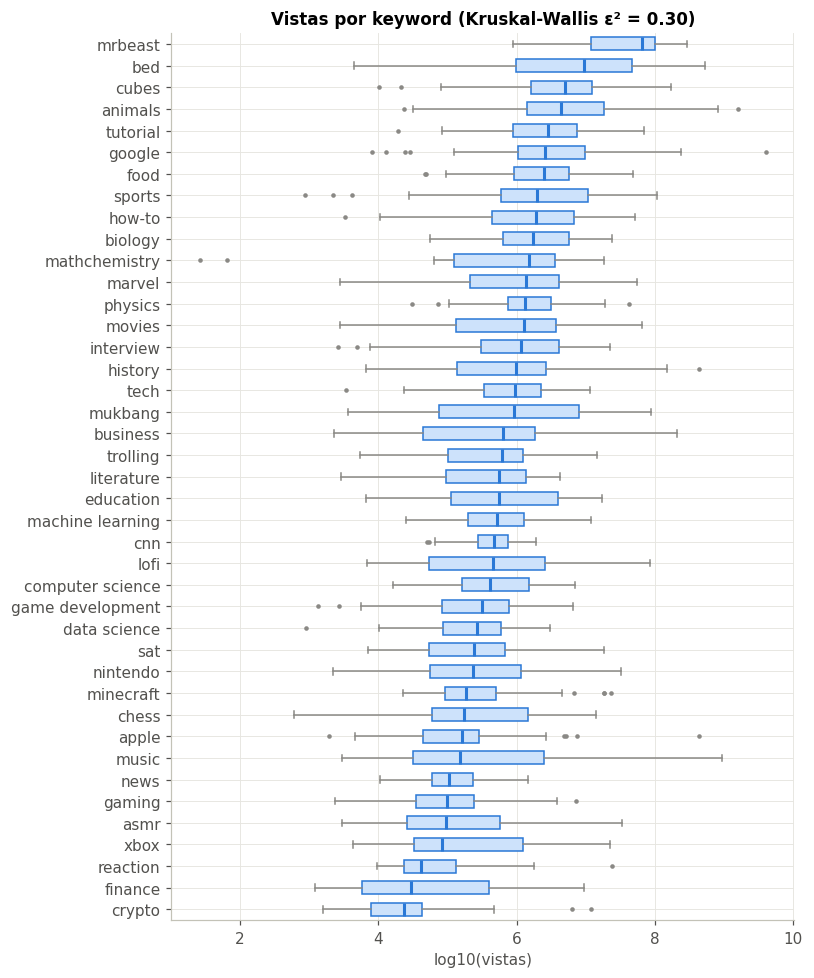

In [ ]:
grupos = [gr["log_views"].values for _, gr in df.groupby("Keyword")]
kw = stats.kruskal(*grupos)
k, n = len(grupos), len(df)
epsilon2 = (kw.statistic - k + 1) / (n - k)

kw_eng = stats.kruskal(*[gr["log_engagement"].dropna().values for _, gr in df.groupby("Keyword")])
eps_eng = (kw_eng.statistic - k + 1) / (df["log_engagement"].notna().sum() - k)
registrar("kruskal_keyword", {"H": round(kw.statistic, 1), "p": float(kw.pvalue), "epsilon2": round(epsilon2, 3),
                              "H_engagement": round(kw_eng.statistic, 1), "epsilon2_engagement": round(eps_eng, 3)})
print(RESULTADOS["kruskal_keyword"])

orden = df.groupby("Keyword")["log_views"].median().sort_values().index
fig, ax = plt.subplots(figsize=(7.5, 9))
ax.boxplot([df.loc[df.Keyword == kw_, "log_views"] for kw_ in orden], vert=False, widths=0.6,
           patch_artist=True, boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL),
           medianprops=dict(color=AZUL, linewidth=2), whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor="none"))
ax.set_yticks(range(1, len(orden) + 1))
ax.set_yticklabels(orden)
ax.set_xlabel("log10(vistas)")
ax.set_title(f"Vistas por keyword (Kruskal-Wallis ε² = {epsilon2:.2f})")
guardar_fig("fig05_vistas_por_keyword")

### 4.4 El sentimiento cambia segun el tema?

{'chi2': 2387.5, 'gl': 80, 'p': 0.0, 'V_cramer': 0.257}


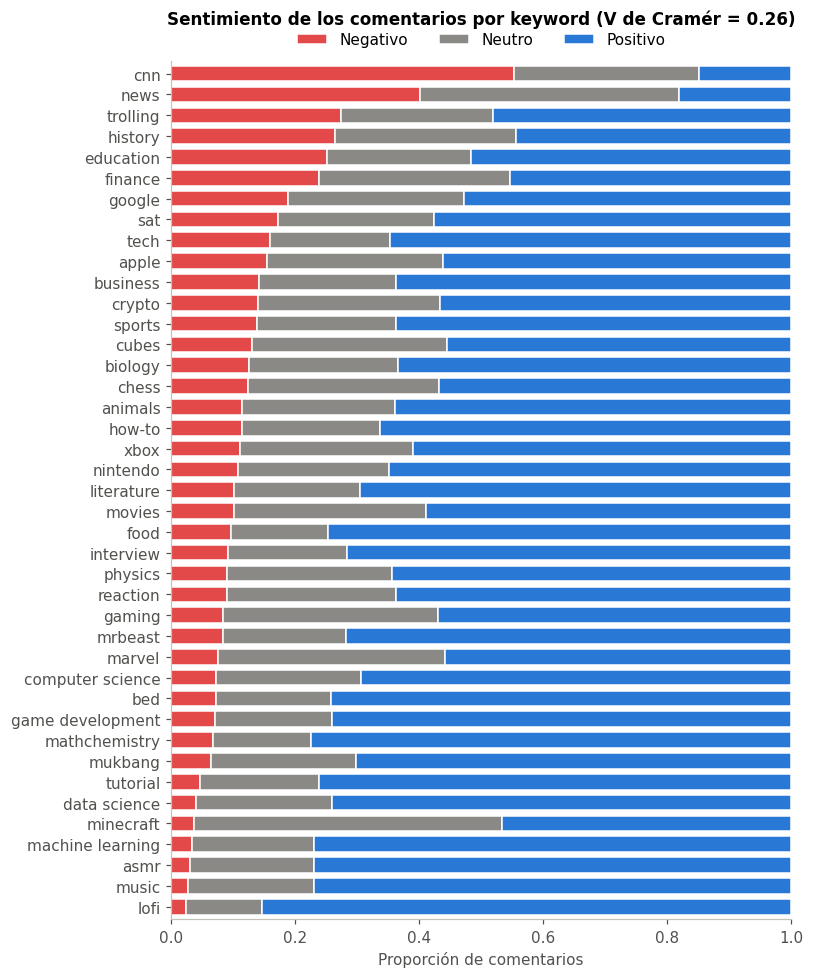

In [ ]:
kw_por_comentario = c.merge(df[["Video ID", "Keyword"]], on="Video ID")["Keyword"]
tabla = pd.crosstab(kw_por_comentario, c["Sentiment"])
chi2_stat, p_chi, gl, _ = stats.chi2_contingency(tabla)
cramer_v = np.sqrt(chi2_stat / (tabla.values.sum() * (min(tabla.shape) - 1)))
registrar("chi2_sentimiento_keyword", {"chi2": round(chi2_stat, 1), "gl": gl, "p": float(p_chi), "V_cramer": round(cramer_v, 3)})
print(RESULTADOS["chi2_sentimiento_keyword"])

prop = tabla.div(tabla.sum(1), axis=0).sort_values(0)
fig, ax = plt.subplots(figsize=(7.5, 9))
izq = np.zeros(len(prop))
for clase, color, etiqueta in [(0, ROJO, "Negativo"), (1, GRIS, "Neutro"), (2, AZUL, "Positivo")]:
    ax.barh(prop.index, prop[clase], left=izq, color=color, label=etiqueta, height=0.75, edgecolor="white", linewidth=1)
    izq += prop[clase].values
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(prop) - 0.4)
ax.set_xlabel("Proporción de comentarios")
ax.grid(False)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title(f"Sentimiento de los comentarios por keyword (V de Cramér = {cramer_v:.2f})", pad=24)
guardar_fig("fig06_sentimiento_por_keyword")
registrar("keywords_mas_negativas", prop[0].sort_values(ascending=False).head(5).round(3).to_dict())
registrar("keywords_mas_positivas", prop[2].sort_values(ascending=False).head(5).round(3).to_dict())

### 4.5 Correlacion parcial el sentimiento sigue importando si quitamos el efecto de la edad y el tema?

Puede que la relacion entre sentimiento y vistas sea solo porque ciertos temas tienen comentarios mas positivos
y tambien mas vistas, la correlacion parcial le quita a las dos variables lo que explican la edad y el tema, y mide
la relacion que queda.

In [ ]:
def spearman_parcial(datos, x, y, controles):
    d = datos[[x, y] + controles].dropna()
    rangos = d.rank()
    Z = np.column_stack([np.ones(len(d)), rangos[controles].values])

    def residuo(col):
        coef = np.linalg.lstsq(Z, rangos[col].values, rcond=None)[0]
        return rangos[col].values - Z @ coef

    r = np.corrcoef(residuo(x), residuo(y))[0, 1]
    gl_ = len(d) - 2 - len(controles)
    t = r * np.sqrt(gl_ / (1 - r ** 2))
    return r, 2 * stats.t.sf(abs(t), gl_)

dum_kw = pd.get_dummies(df["Keyword"], prefix="kw", drop_first=True).astype(float)
dfp = pd.concat([df, dum_kw], axis=1)
controles_1 = ["log_edad"] + list(dum_kw.columns)
controles_2 = ["log_edad", "log_likes_coment"] + list(dum_kw.columns)

filas = []
for x in ["sent_media", "sent_ponderado", "pct_neg", "largo_medio"]:
    for y in ["log_views", "log_engagement"]:
        r0, p0 = stats.spearmanr(df[x], df[y], nan_policy="omit")
        r1, p1 = spearman_parcial(dfp, x, y, controles_1)
        r2, p2 = spearman_parcial(dfp, x, y, controles_2)
        filas.append([x, y, r0, p0, r1, p1, r2, p2])
parcial = pd.DataFrame(filas, columns=["variable", "objetivo", "rho_simple", "p_simple",
                                       "rho_parcial_edad_tema", "p_1", "rho_parcial_+escala", "p_2"]).round(4)
display(parcial)
registrar("correlacion_parcial", parcial.to_dict(orient="records"))

,variable,objetivo,rho_simple,p_simple,rho_parcial_edad_tema,p_1,rho_parcial_+escala,p_2
0,sent_media,log_views,0.1261,0.0000,0.0432,0.0651,0.1077,0.0000
1,sent_media,log_engagement,0.0651,0.0050,0.0386,0.1002,0.0636,0.0067
2,sent_ponderado,log_views,0.0758,0.0010,0.0170,0.4687,0.0878,0.0002
3,sent_ponderado,log_engagement,0.0631,0.0065,0.0262,0.2648,0.0558,0.0173
4,pct_neg,log_views,-0.0221,0.3392,0.0151,0.5197,-0.1119,0.0000
5,pct_neg,log_engagement,-0.0947,0.0000,-0.0403,0.0861,-0.0962,0.0000
6,largo_medio,log_views,0.0178,0.4417,0.0649,0.0056,-0.0985,0.0000
7,largo_medio,log_engagement,0.0989,0.0000,0.1262,0.0000,0.0616,0.0087


### 4.6 Intervalo de confianza con bootstrap (sentimiento vs engagement)

In [ ]:
d_eng = df[["sent_media", "log_engagement"]].dropna()
boot = stats.bootstrap((d_eng["sent_media"].values, d_eng["log_engagement"].values),
                       lambda a, b: stats.spearmanr(a, b)[0], paired=True, n_resamples=2000,
                       random_state=SEMILLA, method="percentile")
rho = stats.spearmanr(d_eng["sent_media"], d_eng["log_engagement"])[0]
registrar("bootstrap_sent_engagement", {"rho": round(rho, 3), "ic95": [round(boot.confidence_interval.low, 3),
                                                                      round(boot.confidence_interval.high, 3)]})
print(RESULTADOS["bootstrap_sent_engagement"])

{'rho': 0.065, 'ic95': [0.019, 0.109]}


### 4.7 Videos con mucho vs poco engagement dentro de su mismo tema
se partio del engagement en cuartiles dentro de cada keyword y comparamos el cuartil de arriba con el de abajo

In [ ]:
df["cuartil_eng_kw"] = df.groupby("Keyword")["log_engagement"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 4, labels=False))
alto = df[df["cuartil_eng_kw"] == 3]
bajo = df[df["cuartil_eng_kw"] == 0]

filas = []
for var in ["sent_media", "pct_neg", "pct_pos", "largo_medio", "pct_preguntas", "pct_exclamacion"]:
    u = stats.mannwhitneyu(alto[var], bajo[var])
    cliff = 2 * u.statistic / (len(alto) * len(bajo)) - 1  # delta de Cliff, va de -1 a 1
    filas.append([var, alto[var].median(), bajo[var].median(), u.pvalue, cliff])
mw = pd.DataFrame(filas, columns=["variable", "mediana_alto", "mediana_bajo", "p_valor", "delta_cliff"]).round(4)
display(mw)
registrar("mann_whitney_engagement", mw.to_dict(orient="records"))

,variable,mediana_alto,mediana_bajo,p_valor,delta_cliff
0,sent_media,0.6,0.6,0.4913,0.0257
1,pct_neg,0.0,0.1,0.1507,-0.0499
2,pct_pos,0.7,0.7,0.6416,0.0173
3,largo_medio,155.4,139.9,0.0260,0.0832
4,pct_preguntas,0.0,0.0,0.9354,-0.0028
5,pct_exclamacion,0.2,0.2,0.4250,0.0295


### 4.8 Como crecen las vistas con la edad del video
Si la pendiente en escala log-log es menor que 1, las vistas crecen mas lento que el tiempo.

{'pendiente': 0.619, 'ic95': [0.584, 0.655], 'r2': 0.383}


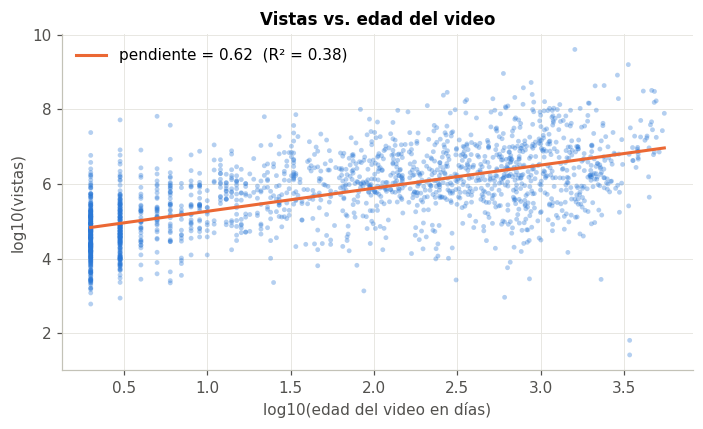

In [ ]:
reg = stats.linregress(df["log_edad"], df["log_views"])
registrar("elasticidad_edad", {"pendiente": round(reg.slope, 3),
                               "ic95": [round(reg.slope - 1.96 * reg.stderr, 3), round(reg.slope + 1.96 * reg.stderr, 3)],
                               "r2": round(reg.rvalue ** 2, 3)})
print(RESULTADOS["elasticidad_edad"])

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(df["log_edad"], df["log_views"], s=10, color=AZUL, alpha=0.35, edgecolor="none")
xs = np.linspace(df["log_edad"].min(), df["log_edad"].max(), 50)
ax.plot(xs, reg.intercept + reg.slope * xs, color=NARANJA, linewidth=2,
        label=f"pendiente = {reg.slope:.2f}  (R² = {reg.rvalue**2:.2f})")
ax.set_xlabel("log10(edad del video en días)")
ax.set_ylabel("log10(vistas)")
ax.set_title("Vistas vs. edad del video")
ax.legend(frameon=False)
guardar_fig("fig07_vistas_vs_edad")

### 4.9 La gente le da mas likes a los comentarios positivos o a los negativos?
se comparo en cada video el sentimiento normal con el ponderado por likes

In [ ]:
w = stats.wilcoxon(df["sent_ponderado"], df["sent_media"])
dif = df["sent_ponderado"] - df["sent_media"]
registrar("wilcoxon_ponderado", {"mediana_diferencia": round(dif.median(), 4), "media_diferencia": round(dif.mean(), 4),
                                 "p": float(w.pvalue)})
r_likes_sent = stats.spearmanr(c["Likes"], c["polaridad"])
registrar("spearman_likes_vs_polaridad_comentario", {"rho": round(r_likes_sent[0], 3), "p": float(r_likes_sent[1])})
print(RESULTADOS["wilcoxon_ponderado"], RESULTADOS["spearman_likes_vs_polaridad_comentario"])

{'mediana_diferencia': -0.015, 'media_diferencia': -0.0328, 'p': 3.0242939931242334e-38} {'rho': -0.075, 'p': 6.40986493595524e-24}


### 4.10 Palabras que mas se asocian a cada sentimiento y al buen desempeño
se cuentan las palabras (bag of words) y con la prueba chi-cuadrado vemos cuales aparecen mucho mas en un grupo que en otro

In [ ]:
bow = CountVectorizer(stop_words="english", min_df=10, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
Xb = bow.fit_transform(c["Comment"])
vocab = np.array(bow.get_feature_names_out())

def palabras_top(X, y_bin, n=15):
    puntaje, _ = chi2(X, y_bin)
    frec_grupo = np.asarray(X[y_bin == 1].mean(0)).ravel()
    frec_resto = np.asarray(X[y_bin == 0].mean(0)).ravel()
    # nos quedamos solo con las palabras que son mas frecuentes en el grupo
    return vocab[np.argsort(-puntaje * (frec_grupo > frec_resto))[:n]].tolist()

terminos = {
    "negativo": palabras_top(Xb, (c["Sentiment"] == 0).astype(int).values),
    "positivo": palabras_top(Xb, (c["Sentiment"] == 2).astype(int).values),
}
Xv = bow.transform(df["texto_comentarios"])
terminos["alto_desempeno"] = palabras_top(Xv, df["alto_desempeno"].values)
terminos["bajo_desempeno"] = palabras_top(Xv, 1 - df["alto_desempeno"].values)
registrar("terminos_chi2", terminos)
for grupo, palabras in terminos.items():
    print(f"{grupo:>15}: {', '.join(palabras)}")

       negativo: people, don, trump, documents, hate, ridiculous, worst, bad, wrong, problem, worse, pumps, sad, caused, pay
       positivo: love, thank, great, amazing, thanks, videos, good, really, best, video, awesome, appreciate, excited, cool, content
 alto_desempeno: song, ly, decade, algorithm, dad, level, time, types, gibi, hrithik, linus, gordon, elon, water, makes
 bajo_desempeno: je, et, btc, le, est, sony, trade, ich, merci, les, mais, pour, sur, des, vous


### 4.11 Que tan confiable es la etiqueta de sentimiento?
se entreno un clasificador y reviso los comentarios donde el modelo, sin haberlos visto, le da menos del 10% de
probabilidad a la etiqueta que traen, mo quiere decir que esten mal, pero da una idea de cuantas etiquetas son dudosas.

In [ ]:
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
modelo_ruido = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                             LogisticRegression(max_iter=3000, C=3, class_weight="balanced"))
proba = cross_val_predict(modelo_ruido, c["Comment"], c["Sentiment"], groups=c["Video ID"], cv=cv_grupos,
                          method="predict_proba")
p_etiqueta = proba[np.arange(len(c)), c["Sentiment"].values]
sospechosos = c.assign(p_etiqueta=p_etiqueta, pred=proba.argmax(1))[p_etiqueta < 0.10]
registrar("ruido_etiquetas", {"n_sospechosos": len(sospechosos), "pct": round(100 * len(sospechosos) / len(c), 2),
                              "por_clase": sospechosos["Sentiment"].value_counts().to_dict()})
print(RESULTADOS["ruido_etiquetas"])
display(sospechosos.sort_values("p_etiqueta")[["Comment", "Sentiment", "pred", "p_etiqueta"]].head(8))

{'n_sospechosos': 424, 'pct': 2.34, 'por_clase': {1: 156, 2: 153, 0: 115}}


,Comment,Sentiment,pred,p_etiqueta
16719,Thank You so much 👌🏻👍🏻\nEdureka !!\n\n2:44 Int...,2,1,0.003393
3458,The delivery was definitely illegal and unprof...,0,2,0.007378
14016,Hope this will make your life easier..\n\n\n00...,2,1,0.007759
2936,OTHER TUTORIALS AT http://sdp.io/tutorial.\n\n...,2,1,0.009616
12901,Em toda minha vida nunca vi uma leva de jornal...,0,1,0.009952
5739,I’d like to confirm that i’ve been watching yo...,1,2,0.011733
17936,With great power comes great responsibility......,0,2,0.013764
14991,Malheureusement c'est toujours les mêmes promo...,0,1,0.013784


## 5. Modelo A: clasificador de sentimiento

Aunque el dataset ya trae la etiqueta, cuando el modelo este funcionando van a llegar comentarios nuevos sin
etiqueta, entonces necesitamos un modelo que la ponga.

Se separo el entrenamiento y prueba por video, o sea que los 10 comentarios de un video quedan todos
del mismo lado, Si no se hace, el modelo aprende el tema del video y los resultados salen mejores de lo que son.
Como metrica usamos F1-macro, que le da el mismo peso a las tres clases, la negativa es solo el 13%

In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_tr, idx_te = next(gss.split(c, groups=c["Video ID"]))
c_tr, c_te = c.iloc[idx_tr], c.iloc[idx_te]
Xtr, ytr, gtr = c_tr["Comment"], c_tr["Sentiment"], c_tr["Video ID"]
Xte, yte = c_te["Comment"], c_te["Sentiment"]

def tfidf_palabras():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

candidatos_A = {
    "Línea base (clase mayoritaria)": make_pipeline(CountVectorizer(), DummyClassifier(strategy="most_frequent")),
    "BoW + Naive Bayes (Complement)": make_pipeline(CountVectorizer(ngram_range=(1, 2), min_df=2), ComplementNB()),
    "TF-IDF + Naive Bayes (Complement)": make_pipeline(tfidf_palabras(), ComplementNB()),
    "TF-IDF + Regresión Logística": make_pipeline(tfidf_palabras(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "TF-IDF + SVM lineal": make_pipeline(tfidf_palabras(), LinearSVC(class_weight="balanced")),
    "TF-IDF caracteres + SVM lineal": make_pipeline(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=5, sublinear_tf=True),
        LinearSVC(class_weight="balanced")),
}

filas = []
for nombre, modelo in candidatos_A.items():
    t0 = time.time()
    r = cross_validate(modelo, Xtr, ytr, groups=gtr, cv=cv_grupos, scoring=["f1_macro", "accuracy"])
    filas.append([nombre, r["test_f1_macro"].mean(), r["test_f1_macro"].std(), r["test_accuracy"].mean(), time.time() - t0])
    print(f"{nombre:<36} F1-macro = {filas[-1][1]:.3f} +- {filas[-1][2]:.3f}")
comp_A = pd.DataFrame(filas, columns=["modelo", "f1_macro_cv", "f1_macro_std", "accuracy_cv", "segundos"]).round(4)
registrar("modelo_A_comparacion", comp_A.to_dict(orient="records"))

Línea base (clase mayoritaria)       F1-macro = 0.255 +- 0.002
BoW + Naive Bayes (Complement)       F1-macro = 0.608 +- 0.010
TF-IDF + Naive Bayes (Complement)    F1-macro = 0.504 +- 0.009
TF-IDF + Regresión Logística         F1-macro = 0.668 +- 0.011
TF-IDF + SVM lineal                  F1-macro = 0.664 +- 0.015
TF-IDF caracteres + SVM lineal       F1-macro = 0.677 +- 0.011


### 5.1 Ajuste del mejor modelo
Gano el que usa pedazos de palabras (n-gramas de caracteres) con SVM, tiene sentido porque en YouTube la gente
escribe con errores, alarga palabras, usa emojis y a veces escribe en otros idioma, se prueban varios valores
de C (entre mas pequeno, mas simple el modelo)

In [ ]:
pipe_A = Pipeline([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=5, sublinear_tf=True)),
                   ("clf", LinearSVC(class_weight="balanced"))])
grid_A = GridSearchCV(pipe_A, {"clf__C": [0.05, 0.15, 0.5]}, cv=cv_grupos, scoring="f1_macro", n_jobs=-1)
grid_A.fit(Xtr, ytr, groups=gtr)
print("Mejor C:", grid_A.best_params_, "| F1-macro en validacion cruzada:", round(grid_A.best_score_, 4))

pred_te = grid_A.predict(Xte)
nombres_clases = ["negativo", "neutro", "positivo"]
rep = classification_report(yte, pred_te, target_names=nombres_clases, output_dict=True)
registrar("modelo_A_final", {
    "params": {k_: str(v_) for k_, v_ in grid_A.best_params_.items()},
    "f1_macro_cv": round(grid_A.best_score_, 4),
    "f1_macro_test": round(f1_score(yte, pred_te, average="macro"), 4),
    "accuracy_test": round(accuracy_score(yte, pred_te), 4),
    "por_clase": {k_: {m: round(rep[k_][m], 3) for m in ["precision", "recall", "f1-score"]} for k_ in nombres_clases},
    "n_combinaciones_grid": len(grid_A.cv_results_["params"])})
print(classification_report(yte, pred_te, target_names=nombres_clases))

Mejor C: {'clf__C': 0.15} | F1-macro en validacion cruzada: 0.6878
              precision    recall  f1-score   support

    negativo       0.52      0.59      0.55       480
      neutro       0.65      0.64      0.65       898
    positivo       0.88      0.86      0.87      2256

    accuracy                           0.77      3634
   macro avg       0.68      0.70      0.69      3634
weighted avg       0.78      0.77      0.77      3634



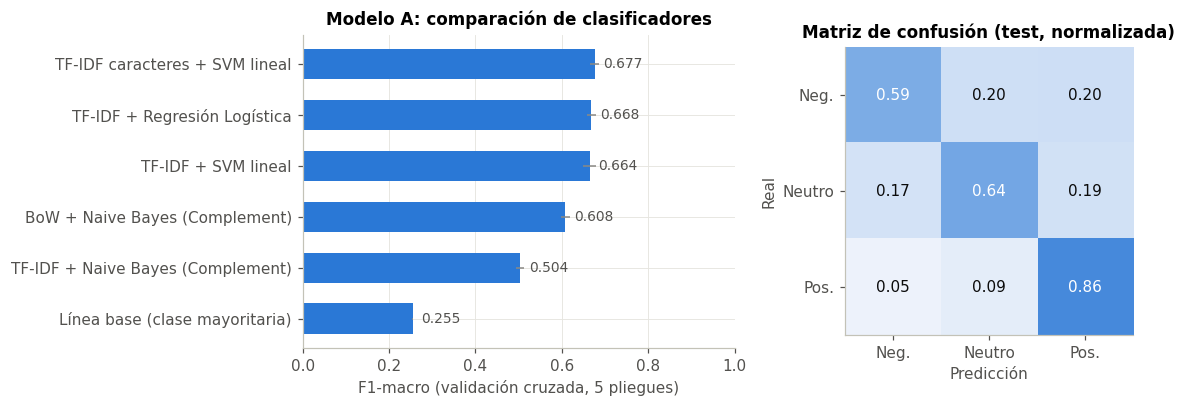

In [ ]:
cm = confusion_matrix(yte, pred_te, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
orden_A = comp_A.sort_values("f1_macro_cv")
axes[0].barh(orden_A["modelo"], orden_A["f1_macro_cv"], xerr=orden_A["f1_macro_std"], color=AZUL, height=0.6,
             error_kw=dict(ecolor=GRIS, lw=1))
for i, val in enumerate(orden_A["f1_macro_cv"]):
    axes[0].text(val + 0.02, i, f"{val:.3f}", va="center", color=TINTA2, fontsize=9)
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("F1-macro (validación cruzada, 5 pliegues)")
axes[0].set_title("Modelo A: comparación de clasificadores")

im = axes[1].imshow(cm, cmap=LinearSegmentedColormap.from_list("seq", ["#f7f9fd", AZUL]), vmin=0, vmax=1)
etq = ["Neg.", "Neutro", "Pos."]
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(etq)
axes[1].set_yticks(range(3))
axes[1].set_yticklabels(etq)
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Real")
axes[1].grid(False)
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else TINTA)
axes[1].set_title("Matriz de confusión (test, normalizada)")
guardar_fig("fig08_modelo_A")

### 5.2 Curva de aprendizaje: mejoraria con mas comentarios?

In [ ]:
tam, sc_tr, sc_va = learning_curve(grid_A.best_estimator_, Xtr, ytr, groups=gtr, cv=cv_grupos, scoring="f1_macro",
                                   train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1)
curva_A = pd.DataFrame({"n": tam, "train": sc_tr.mean(1), "validacion": sc_va.mean(1)}).round(4)
registrar("curva_aprendizaje_A", curva_A.to_dict(orient="list"))
display(curva_A)

,n,train,validacion
0,1163,0.9153,0.5949
1,3782,0.8916,0.6416
2,6400,0.8753,0.6597
3,9018,0.8621,0.6776
4,11637,0.8574,0.6871


## 6. Modelo B: prediccion del desempeño del video

Lo que predecimos es log10(vistas), se usa el logaritmo porque las vistas van desde decenas hasta miles de millones,
y sin el logaritmo el error lo dominarian los pocos videos virales.

se agrupan las variables en bloques para despues ver cuanto aporta cada uno:

- S (sentimiento): sentimiento medio, desviacion, % negativos y positivos, ponderado por likes y el del comentario top.
- L (como escriben): largo medio, % de preguntas y % de exclamaciones.
- T (texto): TF-IDF de los 10 comentarios juntos, reducido a 100 columnas con SVD.
- E (interaccion): likes totales y maximos en los comentarios.
- M (datos del video): edad, keyword, largo del titulo, si el titulo tiene numero o pregunta, dia de publicacion.

No se usan los Likes ni los Comments del video, porque son resultado del mismo desempeño que queremos predecir.

In [ ]:
BLOQUES = {
    "S": ["sent_media", "sent_std", "pct_neg", "pct_pos", "sent_ponderado", "sent_top"],
    "L": ["largo_medio", "pct_preguntas", "pct_exclamacion"],
    "E": ["log_likes_coment", "log_likes_coment_max"],
    "M": ["log_edad", "largo_titulo", "titulo_pregunta", "titulo_numero", "dia_semana"],
}

def construir_preproceso(bloques, escalar=True):
    # arma el ColumnTransformer segun los bloques que le pidamos
    numericas = [col for b in bloques if b in BLOQUES for col in BLOQUES[b]]
    pasos = []
    if numericas:
        pasos.append(("num", StandardScaler() if escalar else "passthrough", numericas))
    if "T" in bloques:
        texto = make_pipeline(TfidfVectorizer(min_df=3, max_df=0.9, sublinear_tf=True, stop_words="english",
                                              max_features=30000),
                              TruncatedSVD(n_components=100, random_state=SEMILLA))
        pasos.append(("txt", texto, "texto_comentarios"))
    if "M" in bloques:
        pasos.append(("kw", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Keyword"]))
    return ColumnTransformer(pasos)

y_B = df["log_views"]
idx_trB, idx_teB = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEMILLA, stratify=df["Keyword"])
Xtr_B, Xte_B = df.iloc[idx_trB], df.iloc[idx_teB]
ytr_B, yte_B = y_B.iloc[idx_trB], y_B.iloc[idx_teB]

kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
METRICAS_REG = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

def evaluar_cv(modelo, X, y):
    r = cross_validate(modelo, X, y, cv=kf, scoring=METRICAS_REG, n_jobs=-1)
    return r["test_r2"].mean(), r["test_r2"].std(), -r["test_mae"].mean(), -r["test_rmse"].mean()

def gradient_boosting():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEMILLA)

### 6.1 Cuanto aporta cada bloque de variables
se deja fijo el algoritmo (Gradient Boosting) y se van sumando bloques, asi respondemos la pregunta principal del
proyecto: los comentarios sirven para predecir el desempeño?

S (solo sentimiento)               R2 = -0.039 +- 0.059  MAE = 0.885
S+L                                R2 = -0.060 +- 0.073  MAE = 0.896
S+L+T (todo el texto)              R2 = 0.362 +- 0.049  MAE = 0.684
S+L+T+E (todo lo de comentarios)   R2 = 0.627 +- 0.053  MAE = 0.487
M (solo metadatos)                 R2 = 0.581 +- 0.056  MAE = 0.543
M+S+L+T                            R2 = 0.622 +- 0.042  MAE = 0.499
Completo (M+S+L+T+E)               R2 = 0.730 +- 0.042  MAE = 0.411


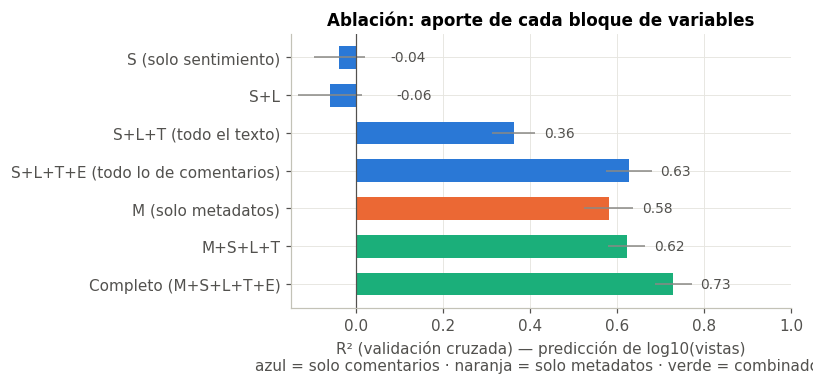

In [ ]:
configs = {"S (solo sentimiento)": ["S"], "S+L": ["S", "L"], "S+L+T (todo el texto)": ["S", "L", "T"],
           "S+L+T+E (todo lo de comentarios)": ["S", "L", "T", "E"], "M (solo metadatos)": ["M"],
           "M+S+L+T": ["M", "S", "L", "T"], "Completo (M+S+L+T+E)": ["M", "S", "L", "T", "E"]}
filas = []
for nombre, bloques in configs.items():
    modelo = make_pipeline(construir_preproceso(bloques, escalar=False), gradient_boosting())
    r2m, r2s, mae, rmse = evaluar_cv(modelo, Xtr_B, ytr_B)
    filas.append([nombre, r2m, r2s, mae, rmse])
    print(f"{nombre:<34} R2 = {r2m:.3f} +- {r2s:.3f}  MAE = {mae:.3f}")
ablacion = pd.DataFrame(filas, columns=["configuracion", "r2_cv", "r2_std", "mae_cv", "rmse_cv"]).round(4)
registrar("ablacion", ablacion.to_dict(orient="records"))

def color_config(nombre):
    if nombre.startswith("M ("):
        return NARANJA   # solo datos del video
    if nombre.startswith("S"):
        return AZUL      # solo comentarios
    return AQUA          # combinados

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(ablacion["configuracion"][::-1], ablacion["r2_cv"][::-1], xerr=ablacion["r2_std"][::-1],
        color=[color_config(n) for n in ablacion["configuracion"][::-1]], height=0.6, error_kw=dict(ecolor=GRIS, lw=1))
for i, (val, sd) in enumerate(zip(ablacion["r2_cv"][::-1], ablacion["r2_std"][::-1])):
    ax.text(max(val, 0) + sd + 0.02, i, f"{val:.2f}", va="center", color=TINTA2, fontsize=9)
ax.axvline(0, color=TINTA2, lw=0.8)
ax.set_xlim(-0.15, 1)
ax.set_xlabel("R² (validación cruzada) — predicción de log10(vistas)\n"
              "azul = solo comentarios · naranja = solo metadatos · verde = combinados")
ax.set_title("Ablación: aporte de cada bloque de variables")
guardar_fig("fig09_ablacion")

### 6.2 Comparacion de algoritmos con todas las variables

In [ ]:
TODOS = ["M", "S", "L", "T", "E"]
candidatos_B = {
    "Línea base (media)": make_pipeline(construir_preproceso(TODOS), DummyRegressor()),
    "Ridge (lineal regularizado)": make_pipeline(construir_preproceso(TODOS), Ridge(alpha=10)),
    "Random Forest": make_pipeline(construir_preproceso(TODOS, escalar=False),
                                   RandomForestRegressor(n_estimators=400, min_samples_leaf=3, n_jobs=-1, random_state=SEMILLA)),
    "Gradient Boosting (HistGB)": make_pipeline(construir_preproceso(TODOS, escalar=False), gradient_boosting()),
}
# ensamble: promedia Ridge y Gradient Boosting, si se equivocan en cosas distintas el promedio sale mejor
candidatos_B["Ensamble (Ridge + HistGB)"] = VotingRegressor([
    ("ridge", candidatos_B["Ridge (lineal regularizado)"]), ("hgb", candidatos_B["Gradient Boosting (HistGB)"])])

filas = []
for nombre, modelo in candidatos_B.items():
    r2m, r2s, mae, rmse = evaluar_cv(modelo, Xtr_B, ytr_B)
    filas.append([nombre, r2m, r2s, mae, rmse])
    print(f"{nombre:<30} R2 = {r2m:.3f} +- {r2s:.3f}  MAE = {mae:.3f}  RMSE = {rmse:.3f}")
comp_B = pd.DataFrame(filas, columns=["modelo", "r2_cv", "r2_std", "mae_cv", "rmse_cv"]).round(4)
registrar("modelo_B_comparacion", comp_B.to_dict(orient="records"))

Línea base (media)             R2 = -0.004 +- 0.005  MAE = 0.879  RMSE = 1.094
Ridge (lineal regularizado)    R2 = 0.739 +- 0.046  MAE = 0.395  RMSE = 0.555
Random Forest                  R2 = 0.713 +- 0.046  MAE = 0.429  RMSE = 0.582
Gradient Boosting (HistGB)     R2 = 0.730 +- 0.042  MAE = 0.411  RMSE = 0.565
Ensamble (Ridge + HistGB)      R2 = 0.752 +- 0.044  MAE = 0.385  RMSE = 0.541


### 6.3 Ajuste de hiperparametros y prueba final
se ajusta el Gradient Boosting con GridSearchCV y arma el modelo final con el que gano en 6.2. El 20% de prueba
no se ha usado en nada hasta aqui, por eso es la medida mas honesta de que tan bien funciona

In [ ]:
pipe_B = Pipeline([("prep", construir_preproceso(TODOS, escalar=False)),
                   ("reg", HistGradientBoostingRegressor(random_state=SEMILLA))])
grid_B = GridSearchCV(pipe_B, {"reg__learning_rate": [0.03, 0.06], "reg__max_iter": [400],
                               "reg__max_leaf_nodes": [15, 31], "reg__l2_regularization": [0.0, 1.0]},
                      cv=kf, scoring="r2", n_jobs=-1)
grid_B.fit(Xtr_B, ytr_B)
print("Mejores hiperparametros:", grid_B.best_params_, "| R2 en validacion cruzada:", round(grid_B.best_score_, 4))

ganador_B = comp_B.loc[comp_B["r2_cv"].idxmax(), "modelo"]
if ganador_B.startswith("Ensamble"):
    modelo_B = VotingRegressor([("ridge", candidatos_B["Ridge (lineal regularizado)"]),
                                ("hgb", grid_B.best_estimator_)]).fit(Xtr_B, ytr_B)
elif ganador_B.startswith("Ridge"):
    modelo_B = candidatos_B["Ridge (lineal regularizado)"].fit(Xtr_B, ytr_B)
else:
    modelo_B = grid_B.best_estimator_
print("Modelo final:", ganador_B)

pred_B = modelo_B.predict(Xte_B)
mae_test = mean_absolute_error(yte_B, pred_B)
registrar("modelo_B_final", {"modelo": ganador_B,
                             "params": {k_: str(v_) for k_, v_ in grid_B.best_params_.items()},
                             "r2_cv": round(grid_B.best_score_, 4), "r2_test": round(r2_score(yte_B, pred_B), 4),
                             "mae_test_log": round(mae_test, 4),
                             "rmse_test_log": round(np.sqrt(mean_squared_error(yte_B, pred_B)), 4),
                             "spearman_test": round(stats.spearmanr(yte_B, pred_B)[0], 4),
                             "factor_error_tipico": round(10 ** mae_test, 2),  # cuantas veces se equivoca, en promedio
                             "n_combinaciones_grid": len(grid_B.cv_results_["params"])})
print(RESULTADOS["modelo_B_final"])

Mejores hiperparametros: {'reg__l2_regularization': 0.0, 'reg__learning_rate': 0.03, 'reg__max_iter': 400, 'reg__max_leaf_nodes': 15} | R2 en validacion cruzada: 0.7349
Modelo final: Ensamble (Ridge + HistGB)
{'modelo': 'Ensamble (Ridge + HistGB)', 'params': {'reg__l2_regularization': '0.0', 'reg__learning_rate': '0.03', 'reg__max_iter': '400', 'reg__max_leaf_nodes': '15'}, 'r2_cv': 0.7349, 'r2_test': 0.7971, 'mae_test_log': 0.3188, 'rmse_test_log': 0.4599, 'spearman_test': 0.889, 'factor_error_tipico': 2.08, 'n_combinaciones_grid': 8}


### 6.4 Que variables pesan mas (importancia por permutacion)
se desordena una variable a la vez en los datos de prueba y se revisa cuanto empeora el R², entre mas empeora, mas
importante es esa variable para el modelo

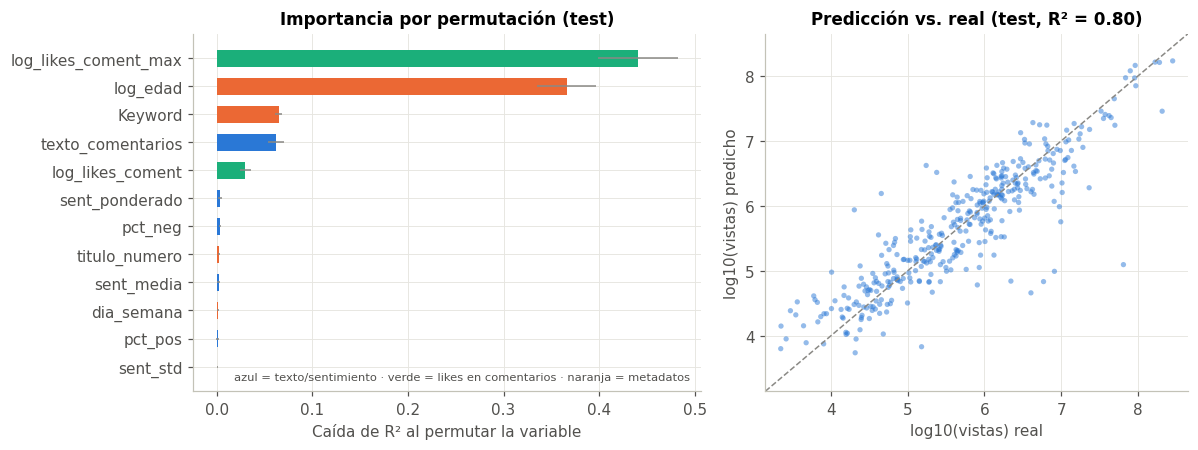

In [ ]:
cols_entrada = [col for b in TODOS if b in BLOQUES for col in BLOQUES[b]] + ["texto_comentarios", "Keyword"]
pi = permutation_importance(modelo_B, Xte_B[cols_entrada], yte_B, n_repeats=5,
                            random_state=SEMILLA, scoring="r2", n_jobs=-1)
imp = pd.DataFrame({"variable": cols_entrada, "importancia": pi.importances_mean, "std": pi.importances_std})
imp = imp.sort_values("importancia", ascending=False).round(4)
registrar("importancia_permutacion", imp.to_dict(orient="records"))

bloque_de = {col: b for b, cols in BLOQUES.items() for col in cols}
bloque_de.update({"texto_comentarios": "T", "Keyword": "M"})
color_bloque = {"S": AZUL, "L": AZUL, "T": AZUL, "E": AQUA, "M": NARANJA}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
top_imp = imp.head(12)[::-1]
axes[0].barh(top_imp["variable"], top_imp["importancia"], xerr=top_imp["std"],
             color=[color_bloque[bloque_de[x]] for x in top_imp["variable"]], height=0.6, error_kw=dict(ecolor=GRIS, lw=1))
axes[0].set_xlabel("Caída de R² al permutar la variable")
axes[0].set_title("Importancia por permutación (test)")
axes[0].text(0.98, 0.03, "azul = texto/sentimiento · verde = likes en comentarios · naranja = metadatos",
             transform=axes[0].transAxes, ha="right", fontsize=7.5, color=TINTA2)
axes[1].scatter(yte_B, pred_B, s=12, color=AZUL, alpha=0.5, edgecolor="none")
lim = [min(yte_B.min(), pred_B.min()) - 0.2, max(yte_B.max(), pred_B.max()) + 0.2]
axes[1].plot(lim, lim, color=GRIS, lw=1, ls="--")
axes[1].set_xlim(lim)
axes[1].set_ylim(lim)
axes[1].set_xlabel("log10(vistas) real")
axes[1].set_ylabel("log10(vistas) predicho")
axes[1].set_title(f"Predicción vs. real (test, R² = {RESULTADOS['modelo_B_final']['r2_test']:.2f})")
guardar_fig("fig10_modelo_B")

### 6.5 Basta con un solo modelo?
Las vistas miden alcance, pero un video puede tener pocas vistas y una audiencia muy metida, por eso se prueba el
mismo esquema con otros dos objetivos, el engagement (likes / vistas) y si al video le fue mejor que a la mitad de
los videos de su mismo tema

In [ ]:
d_e = df.dropna(subset=["log_engagement"])
filas = []
opciones = [("Solo comentarios (S+L+T+E)", ["S", "L", "T", "E"]), ("Completo", TODOS)]
for nombre, bloques in opciones:
    modelo = make_pipeline(construir_preproceso(bloques, escalar=False), gradient_boosting())
    r2m, r2s, mae, rmse = evaluar_cv(modelo, d_e, d_e["log_engagement"])
    filas.append(["engagement (regresión)", nombre, "R²", r2m, r2s])

skf = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
for nombre, bloques in opciones:
    for alg, clf in [("LogReg", LogisticRegression(max_iter=3000, C=0.5)),
                     ("HistGB", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEMILLA))]:
        modelo = make_pipeline(construir_preproceso(bloques, escalar=(alg == "LogReg")), clf)
        r = cross_validate(modelo, df, df["alto_desempeno"], cv=skf, scoring=["roc_auc", "f1"], n_jobs=-1)
        filas.append([f"alto desempeño relativo ({alg})", nombre, "ROC-AUC", r["test_roc_auc"].mean(), r["test_roc_auc"].std()])
        filas.append([f"alto desempeño relativo ({alg})", nombre, "F1", r["test_f1"].mean(), r["test_f1"].std()])
multi = pd.DataFrame(filas, columns=["objetivo", "variables", "metrica", "valor", "std"]).round(4)
display(multi)
registrar("objetivos_complementarios", multi.to_dict(orient="records"))

,objetivo,variables,metrica,valor,std
0,engagement (regresión),Solo comentarios (S+L+T+E),R²,0.2333,0.0234
1,engagement (regresión),Completo,R²,0.4790,0.0251
2,alto desempeño relativo (LogReg),Solo comentarios (S+L+T+E),ROC-AUC,0.7938,0.0082
3,alto desempeño relativo (LogReg),Solo comentarios (S+L+T+E),F1,0.7169,0.0119
4,alto desempeño relativo (HistGB),Solo comentarios (S+L+T+E),ROC-AUC,0.7979,0.0065
5,alto desempeño relativo (HistGB),Solo comentarios (S+L+T+E),F1,0.7134,0.0098
6,alto desempeño relativo (LogReg),Completo,ROC-AUC,0.8648,0.0107
7,alto desempeño relativo (LogReg),Completo,F1,0.7755,0.0134
8,alto desempeño relativo (HistGB),Completo,ROC-AUC,0.8339,0.0108
9,alto desempeño relativo (HistGB),Completo,F1,0.7517,0.0229


### 6.6 Curva de aprendizaje del modelo B

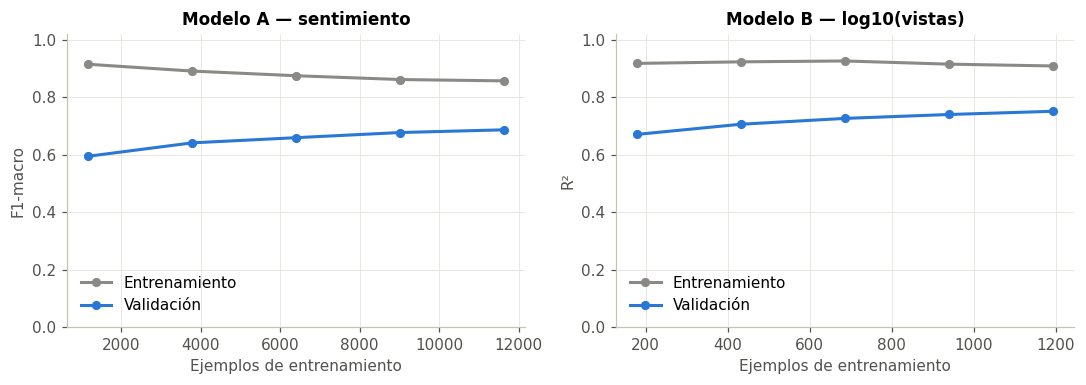

In [ ]:
tam, sc_tr, sc_va = learning_curve(modelo_B, Xtr_B, ytr_B, cv=kf, scoring="r2",
                                   train_sizes=np.linspace(0.15, 1.0, 5), n_jobs=-1)
curva_B = pd.DataFrame({"n": tam, "train": sc_tr.mean(1), "validacion": sc_va.mean(1)}).round(4)
registrar("curva_aprendizaje_B", curva_B.to_dict(orient="list"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, curva, titulo, metrica in [(axes[0], curva_A, "Modelo A — sentimiento", "F1-macro"),
                                   (axes[1], curva_B, "Modelo B — log10(vistas)", "R²")]:
    ax.plot(curva["n"], curva["train"], marker="o", ms=5, lw=2, color=GRIS, label="Entrenamiento")
    ax.plot(curva["n"], curva["validacion"], marker="o", ms=5, lw=2, color=AZUL, label="Validación")
    ax.set_xlabel("Ejemplos de entrenamiento")
    ax.set_ylabel(metrica)
    ax.set_title(titulo)
    ax.legend(frameon=False)
    ax.set_ylim(0, 1.02)
guardar_fig("fig11_curvas_aprendizaje")

## 7. Guardar todo y un ejemplo de monitoreo

se guarda el dataset procesado (con su hash), los dos modelos en archivos .joblib y todas las metricas en un json

Para el monitoreo se usa el PSI, que compara como se distribuye una variable en los datos de entrenamiento y en
datos nuevos, la regla que se usa normalmente: menos de 0.1 todo bien, entre 0.1 y 0.25 toca estar pendiente y
mas de 0.25 toca reentrenar, como ejemplo se toma cuenta que se entrenan con videos de antes de 2022 y que
llegan los de 2022.

In [ ]:
def psi(referencia, actual, bins=10):
    cortes = np.unique(np.quantile(referencia, np.linspace(0, 1, bins + 1)))
    cortes[0], cortes[-1] = -np.inf, np.inf
    p = np.histogram(referencia, cortes)[0] / len(referencia) + 1e-6
    q = np.histogram(actual, cortes)[0] / len(actual) + 1e-6
    return float(np.sum((q - p) * np.log(q / p)))

antes = df[df["Published At"].dt.year < 2022]
nuevos = df[df["Published At"].dt.year == 2022]
monitoreo = {var: round(psi(antes[var], nuevos[var]), 3)
             for var in ["sent_media", "pct_neg", "pct_pos", "largo_medio", "pct_preguntas", "log_likes_coment", "log_views"]}
registrar("psi_pre2022_vs_2022", monitoreo)
print(monitoreo)

{'sent_media': 0.16, 'pct_neg': 0.073, 'pct_pos': 0.2, 'largo_medio': 0.08, 'pct_preguntas': 0.002, 'log_likes_coment': 0.756, 'log_views': 1.146}


In [ ]:
cols_guardar = (["Video ID", "Title", "Keyword", "Published At", "Views", "Likes", "Comments"]
                + [col for cols in BLOQUES.values() for col in cols]
                + ["texto_comentarios", "log_views", "log_engagement", "alto_desempeno"])
df[cols_guardar].to_csv(DATA_DIR / "dataset_modelado.csv", index=False)
registrar("hash_dataset_modelado", hash_archivo(DATA_DIR / "dataset_modelado.csv"))
joblib.dump(grid_A.best_estimator_, OUT_DIR / "modelo_sentimiento.joblib")
joblib.dump(modelo_B, OUT_DIR / "modelo_desempeno.joblib")
with open(OUT_DIR / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=2)
print("Listo, archivos guardados en", OUT_DIR.resolve())

Listo, archivos guardados en /content/resultados


## 8. Traer mas datos con la API de YouTube  en revision

la idea es Traer estadisticas actualizadas, duracion, categoria, tags y hasta 100 comentarios por video.

In [ ]:
USAR_API = False

if USAR_API:
    import requests
    try:
        from google.colab import userdata
        API_KEY = userdata.get("YT_API_KEY")
    except Exception:
        API_KEY = input("API key: ")
    URL = "https://www.googleapis.com/youtube/v3/"

    def detalles_videos(ids):
        filas = []
        for i in range(0, len(ids), 50):  # la API recibe maximo 50 ids por llamada
            r = requests.get(URL + "videos", params={"part": "snippet,statistics,contentDetails",
                                                     "id": ",".join(ids[i:i + 50]), "key": API_KEY}).json()
            for it in r.get("items", []):
                fila = {"Video ID": it["id"], "canal_id": it["snippet"]["channelId"],
                        "categoria": it["snippet"].get("categoryId"),
                        "tags": "|".join(it["snippet"].get("tags", [])),
                        "duracion": it["contentDetails"]["duration"]}
                for k, val in it["statistics"].items():
                    fila["api_" + k] = val
                filas.append(fila)
        return pd.DataFrame(filas)

    def comentarios_video(video_id, maximo=100):
        r = requests.get(URL + "commentThreads", params={"part": "snippet", "videoId": video_id, "maxResults": maximo,
                                                         "order": "relevance", "textFormat": "plainText",
                                                         "key": API_KEY}).json()
        salida = []
        for it in r.get("items", []):
            com = it["snippet"]["topLevelComment"]["snippet"]
            salida.append({"Video ID": video_id, "Comment": com["textDisplay"], "Likes": com["likeCount"],
                           "fecha": com["publishedAt"]})
        return salida

    hoy = pd.Timestamp.now()
    nuevos_videos = detalles_videos(df["Video ID"].tolist())
    nuevos_videos["fecha_extraccion"] = hoy
    nuevos_videos.to_csv(DATA_DIR / f"api_videos_{hoy:%Y%m%d}.csv", index=False)

    nuevos_coment = []
    for i, vid in enumerate(df["Video ID"]):
        try:
            nuevos_coment += comentarios_video(vid)  # si tiene comentarios desactivados devuelve vacio
        except Exception as e:
            print("Error con", vid, e)
        if i % 200 == 0:
            print(f"{i}/{len(df)} videos")
    pd.DataFrame(nuevos_coment).to_csv(DATA_DIR / f"api_comentarios_{hoy:%Y%m%d}.csv", index=False)
    print(nuevos_videos.shape, len(nuevos_coment))

9. Avances III: iteracion del modelo
Aqui se toma como punto de partida lo que quedo en Avances II y se prueban mejoras una por una, cada prueba es una iteracion, se cambia una sola cosa, se mide con la misma validacion cruzada de antes y se compara con el mejor modelo que se tenia hasta ese momento, si mejora se queda y si no se descarta, pero igual queda anotada, todo se guarda en un registro de iteraciones (resultados/registro_iteraciones.csv) y tambien en MLflow, que es una herramienta para llevar el control de los experimentos


### 9.0 Preparacion
Se revisa que herramientas hay disponibles y se crea la funcion que anota cada iteracion

In [1]:
import subprocess, sys, re, zipfile
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.pipeline import FeatureUnion
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

USAR_TRANSFORMERS = True
USAR_MLFLOW = True

def instalar(paquete):
    # instala un paquete con pip, en Colab funciona sin problema
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True, timeout=600,
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        return True
    except Exception:
        return False

# transformers y torch vienen instalados en Colab
HAY_TRANSFORMERS, DISPOSITIVO = False, "cpu"
if USAR_TRANSFORMERS:
    try:
        import torch, transformers
        HAY_TRANSFORMERS = True
        DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
    except ImportError:
        print("No hay torch o transformers, se saltan las iteraciones con modelos preentrenados")

HAY_SBERT = False
if HAY_TRANSFORMERS:
    try:
        import sentence_transformers
        HAY_SBERT = True
    except ImportError:
        if instalar("sentence-transformers"):
            import sentence_transformers
            HAY_SBERT = True

mlflow = None
if USAR_MLFLOW:
    try:
        import mlflow
    except ImportError:
        mlflow = None
        if instalar("mlflow"):
            try:
                import mlflow
            except ImportError:
                mlflow = None
    if mlflow is not None:
        try:
            mlflow.set_tracking_uri("sqlite:///" + str((OUT_DIR / "mlflow.db").resolve()))
            mlflow.set_experiment("proyecto_youtube_avances3")
        except Exception as e:
            print("No se pudo iniciar MLflow:", e)
            mlflow = None

print("transformers:", HAY_TRANSFORMERS, "| sentence-transformers:", HAY_SBERT, "| dispositivo:", DISPOSITIVO,
      "| MLflow:", mlflow is not None)

No se pudo iniciar MLflow: name 'OUT_DIR' is not defined
transformers: True | sentence-transformers: True | dispositivo: cpu | MLflow: False


In [ ]:
registro = []  # aqui queda cada iteracion

def anotar(modelo, it, descripcion, cambio, motivo, herramienta, metrica, cv_media=None, cv_std=None, test=None,
           segundos=None, decision="", etapa="Avances III", extra=None):
    fila = dict(modelo=modelo, iteracion=it, etapa=etapa, descripcion=descripcion, cambio=cambio, motivo=motivo,
                herramienta=herramienta, metrica=metrica, cv_media=cv_media, cv_std=cv_std, test=test,
                segundos=segundos, decision=decision)
    if extra:
        fila.update(extra)
    registro.append(fila)
    if mlflow is not None:
        try:
            with mlflow.start_run(run_name=f"{it} {descripcion}"[:200]):
                mlflow.set_tags({"modelo": modelo, "etapa": etapa, "decision": decision[:250]})
                mlflow.log_params({"cambio": cambio[:250], "herramienta": herramienta[:250], "metrica": metrica})
                for k, val in [("cv_media", cv_media), ("cv_std", cv_std), ("test", test), ("segundos", segundos)]:
                    if val is not None and not pd.isna(val):
                        mlflow.log_metric(k, float(val))
        except Exception as e:
            print("MLflow no pudo guardar la iteracion:", e)

def t_corregido(a, b, k=5):
    # prueba t corregida de Nadeau y Bengio: sirve para ver si la diferencia entre dos modelos evaluados con
    # los mismos pliegues de validacion cruzada es real o puede ser suerte
    d = np.asarray(a) - np.asarray(b)
    var = d.var(ddof=1)
    if var == 0:
        return 0.0, 1.0
    t = d.mean() / np.sqrt((1 / k + 1 / (k - 1)) * var)
    return float(t), float(2 * stats.t.sf(abs(t), k - 1))

### 9.1 Historial de iteraciones de Avances II
Antes de seguir se pasan al registro las iteraciones que ya se habian hecho en Avances II, para tener la historia
completa. Las que mejoraban al mejor modelo de ese momento se marcan como adoptadas

In [ ]:
historia_A = [
    ("A0", "Línea base (clase mayoritaria)", "Siempre predice positivo", "Punto de partida para comparar", "DummyClassifier"),
    ("A1", "BoW + Naive Bayes (Complement)", "Conteo de palabras y Naive Bayes", "Modelo clasico y rapido para texto", "CountVectorizer + ComplementNB"),
    ("A2", "TF-IDF + Naive Bayes (Complement)", "Cambiar conteos por TF-IDF", "TF-IDF le baja el peso a palabras muy comunes", "TfidfVectorizer + ComplementNB"),
    ("A3", "TF-IDF + Regresión Logística", "Cambiar Naive Bayes por regresion logistica con clases balanceadas", "Naive Bayes supone palabras independientes y no maneja bien el desbalance", "LogisticRegression"),
    ("A4", "TF-IDF + SVM lineal", "Cambiar regresion logistica por SVM lineal", "La SVM fue el mejor modelo clasico en el articulo de la UNSM", "LinearSVC"),
    ("A5", "TF-IDF caracteres + SVM lineal", "Usar pedazos de 2 a 4 letras en vez de palabras", "Los comentarios tienen errores de ortografia, emojis y otros idiomas", "TfidfVectorizer(char_wb) + LinearSVC"),
]
mejor = -np.inf
for it, nombre, cambio, motivo, herr in historia_A:
    fila = comp_A[comp_A["modelo"] == nombre].iloc[0]
    if it == "A0":
        decision = "referencia"
    elif fila["f1_macro_cv"] > mejor:
        decision = "adoptada"
    else:
        decision = "descartada"
    mejor = max(mejor, fila["f1_macro_cv"])
    anotar("A", it, nombre, cambio, motivo, herr, "F1-macro", fila["f1_macro_cv"], fila["f1_macro_std"],
           segundos=fila["segundos"], decision=decision, etapa="Avances II")

# A6: el modelo final de Avances II (A5 con C ajustado)
i = grid_A.best_index_
folds_A6 = np.array([grid_A.cv_results_[f"split{k}_test_score"][i] for k in range(cv_grupos.n_splits)])
C_A = float(grid_A.best_params_["clf__C"])
anotar("A", "A6", "A5 con C ajustado", f"Ajustar la regularizacion C (quedo en {C_A})", "Buscar el mejor balance entre simple y preciso",
       "GridSearchCV", "F1-macro", folds_A6.mean(), folds_A6.std(), RESULTADOS["modelo_A_final"]["f1_macro_test"],
       decision="adoptada (modelo final de Avances II)", etapa="Avances II")

historia_B = [
    ("B0", "Línea base (media)", comp_B, "modelo", "Siempre predice el promedio", "Punto de partida", "DummyRegressor"),
    ("B1", "S (solo sentimiento)", ablacion, "configuracion", "Solo variables de sentimiento", "Probar la idea original del proyecto", "HistGradientBoosting"),
    ("B2", "S+L", ablacion, "configuracion", "Agregar forma de escribir", "El largo de los comentarios mostro diferencias en 4.7", "HistGradientBoosting"),
    ("B3", "S+L+T (todo el texto)", ablacion, "configuracion", "Agregar el texto con TF-IDF y SVD", "Las palabras revelan tema, audiencia e idioma", "TF-IDF + TruncatedSVD"),
    ("B4", "S+L+T+E (todo lo de comentarios)", ablacion, "configuracion", "Agregar likes de los comentarios", "La interaccion refleja el tamano de la audiencia", "HistGradientBoosting"),
    ("B5", "Completo (M+S+L+T+E)", ablacion, "configuracion", "Agregar datos del video", "Controlar edad y tema, que pesan mucho", "HistGradientBoosting"),
    ("B6", "Ridge (lineal regularizado)", comp_B, "modelo", "Cambiar a un modelo lineal", "Comparar con un modelo mas simple", "Ridge"),
    ("B7", "Random Forest", comp_B, "modelo", "Cambiar a bosque aleatorio", "Otro tipo de modelo de arboles", "RandomForestRegressor"),
    ("B8", "Ensamble (Ridge + HistGB)", comp_B, "modelo", "Promediar Ridge y Gradient Boosting", "Se equivocan en cosas distintas", "VotingRegressor"),
]
mejor = -np.inf
for it, nombre, tabla_origen, col, cambio, motivo, herr in historia_B:
    fila = tabla_origen[tabla_origen[col] == nombre].iloc[0]
    if it == "B0":
        decision = "referencia"
    elif fila["r2_cv"] > mejor:
        decision = "adoptada"
    else:
        decision = "descartada"
    mejor = max(mejor, fila["r2_cv"])
    anotar("B", it, nombre, cambio, motivo, herr, "R²", fila["r2_cv"], fila["r2_std"], decision=decision, etapa="Avances II")

pd.DataFrame(registro)[["iteracion", "descripcion", "cv_media", "decision"]]

,iteracion,descripcion,cv_media,decision
0,A0,Línea base (clase mayoritaria),0.254600,referencia
1,A1,BoW + Naive Bayes (Complement),0.608000,adoptada
2,A2,TF-IDF + Naive Bayes (Complement),0.504000,descartada
3,A3,TF-IDF + Regresión Logística,0.668000,adoptada
4,A4,TF-IDF + SVM lineal,0.664400,descartada
5,A5,TF-IDF caracteres + SVM lineal,0.676600,adoptada
6,A6,A5 con C ajustado,0.687769,adoptada (modelo final de Avances II)
7,B0,Línea base (media),-0.002200,referencia
8,B1,S (solo sentimiento),-0.063600,descartada
9,B2,S+L,-0.032600,descartada


### 9.2 Modelo A: nuevas iteraciones del clasificador de sentimiento

Se parte del modelo A6 (pedazos de letras + SVM). Cada nueva iteracion se compara con el mejor modelo hasta ese
momento usando los mismos 5 pliegues, y ademas se calcula la prueba t corregida para saber si la diferencia es real

In [ ]:
mascara_A = np.ones(len(Xtr), dtype=bool)  # que comentarios de entrenamiento se usan (todos al inicio)

def evaluar_A(modelo, X_tr=None, X_te=None, mascara=None):
    # validacion cruzada por video + prueba final; la mascara permite quitar comentarios del entrenamiento
    X_tr = Xtr if X_tr is None else X_tr
    X_te = Xte if X_te is None else X_te
    mascara = mascara_A if mascara is None else mascara
    t0 = time.time()
    if isinstance(modelo, GridSearchCV):
        modelo.fit(X_tr[mascara], ytr[mascara], groups=gtr[mascara])
        i = modelo.best_index_
        folds = np.array([modelo.cv_results_[f"split{k}_test_score"][i] for k in range(cv_grupos.n_splits)])
        ajustado = modelo.best_estimator_
    else:
        def un_pliegue(a, b):
            a = a[mascara[a]]  # solo se quitan del entrenamiento, la validacion queda completa
            m = clone(modelo).fit(X_tr.iloc[a], ytr.iloc[a])
            return f1_score(ytr.iloc[b], m.predict(X_tr.iloc[b]), average="macro")
        folds = np.array(joblib.Parallel(n_jobs=-1)(joblib.delayed(un_pliegue)(a, b)
                                                    for a, b in cv_grupos.split(X_tr, ytr, gtr)))
        ajustado = clone(modelo).fit(X_tr[mascara], ytr[mascara])
    pred = ajustado.predict(X_te)
    return dict(folds=folds, cv_media=folds.mean(), cv_std=folds.std(), test=f1_score(yte, pred, average="macro"),
                pred=pred, modelo=ajustado, X_tr=X_tr, X_te=X_te, segundos=time.time() - t0)

campeon_A = dict(id="A6", descripcion="A5 con C ajustado", folds=folds_A6, cv_media=folds_A6.mean(),
                 test=RESULTADOS["modelo_A_final"]["f1_macro_test"], pred=pred_te, modelo=grid_A.best_estimator_,
                 X_tr=Xtr, X_te=Xte)
resultados_A = {"A6": campeon_A}

def decidir_A(it, res, descripcion, cambio, motivo, herramienta):
    global campeon_A
    t, p = t_corregido(res["folds"], campeon_A["folds"])
    dif = res["cv_media"] - campeon_A["cv_media"]
    if dif > 0:
        decision = f"adoptada ({dif:+.3f} frente a {campeon_A['id']}, p = {p:.2f})"
        campeon_A = {**res, "id": it, "descripcion": descripcion}
    else:
        decision = f"descartada ({dif:+.3f} frente a {campeon_A['id']}, p = {p:.2f})"
    resultados_A[it] = {**res, "id": it, "descripcion": descripcion}
    anotar("A", it, descripcion, cambio, motivo, herramienta, "F1-macro", res["cv_media"], res["cv_std"], res["test"],
           res["segundos"], decision, extra={"p_valor": p})
    print(f"{it} {descripcion}: F1 cv = {res['cv_media']:.3f} +- {res['cv_std']:.3f} | test = {res['test']:.3f} | {decision}")

def omitir_A(it, descripcion, cambio, motivo, herramienta, razon):
    anotar("A", it, descripcion, cambio, motivo, herramienta, "F1-macro", decision=f"omitida ({razon})")
    print(f"{it} {descripcion}: omitida ({razon})")

**A7. Palabras y pedazos de letras juntos.** Las palabras capturan el significado (por ejemplo "not good") y los
pedazos de letras capturan errores de escritura y emojis, la idea es que juntas se complementen. Como cambia la
cantidad de variables, se vuelve a ajustar C

In [ ]:
def tfidf_union():
    return FeatureUnion([
        ("palabras", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("letras", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=5, sublinear_tf=True)),
    ])

grid_A7 = GridSearchCV(Pipeline([("tfidf", tfidf_union()), ("clf", LinearSVC(class_weight="balanced"))]),
                       {"clf__C": [0.1, 0.3]}, cv=cv_grupos, scoring="f1_macro", n_jobs=-1)
decidir_A("A7", evaluar_A(grid_A7), "Palabras + letras + SVM",
          "Unir TF-IDF de palabras y de pedazos de letras", "Combinar significado y forma de escribir",
          "FeatureUnion + GridSearchCV")

A7 Palabras + letras + SVM: F1 cv = 0.701 +- 0.008 | test = 0.708 | adoptada (+0.013 frente a A6, p = 0.14)


**A8. Quitar etiquetas dudosas del entrenamiento.** En la parte 4.11 se vio que cerca del 2% de las etiquetas
parecen estar mal. Aqui se buscan esos comentarios solo dentro del entrenamiento y se entrena sin ellos. La prueba
final no se toca, sigue con todas sus etiquetas originales

In [ ]:
detector = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=3000, C=3, class_weight="balanced"))
proba_tr = cross_val_predict(detector, Xtr, ytr, groups=gtr, cv=cv_grupos, method="predict_proba", n_jobs=-1)
sospechoso_tr = proba_tr[np.arange(len(ytr)), ytr.values] < 0.10
print("Comentarios de entrenamiento sospechosos:", sospechoso_tr.sum(), f"({100 * sospechoso_tr.mean():.1f}%)")

res = evaluar_A(clone(campeon_A["modelo"]), X_tr=campeon_A["X_tr"], X_te=campeon_A["X_te"], mascara=~sospechoso_tr)
antes = campeon_A["id"]
decidir_A("A8", res, f"{antes} sin etiquetas dudosas", "Entrenar sin los comentarios con etiqueta dudosa",
          "Las etiquetas con errores confunden al modelo", "cross_val_predict (confident learning)")
if campeon_A["id"] == "A8":
    mascara_A = ~sospechoso_tr  # las siguientes iteraciones tambien entrenan sin esos comentarios

Comentarios de entrenamiento sospechosos: 315 (2.2%)
A8 A7 sin etiquetas dudosas: F1 cv = 0.705 +- 0.008 | test = 0.705 | adoptada (+0.004 frente a A7, p = 0.15)


**A9. Red neuronal.** Se prueba una red neuronal sencilla (perceptron multicapa) sobre el texto resumido en 200
columnas. Es la version de deep learning que se puede correr con scikit-learn sin GPU

In [ ]:
pipe_A9 = Pipeline([("tfidf", tfidf_union()), ("svd", TruncatedSVD(n_components=200, random_state=SEMILLA)),
                    ("escala", StandardScaler()),
                    ("mlp", MLPClassifier(hidden_layer_sizes=(128,), alpha=1e-2, early_stopping=True, max_iter=80,
                                          random_state=SEMILLA))])
decidir_A("A9", evaluar_A(pipe_A9), "Red neuronal (MLP)", "Cambiar la SVM por una red neuronal de una capa oculta",
          "Probar si un modelo no lineal aprende mas del texto", "TruncatedSVD + MLPClassifier")

A9 Red neuronal (MLP): F1 cv = 0.632 +- 0.014 | test = 0.616 | descartada (-0.073 frente a A8, p = 0.00)


**A10. Transformer preentrenado sin entrenar (zero-shot).** Se usa el modelo twitter-xlm-roberta-base-sentiment, que
ya viene entrenado para clasificar sentimiento en tweets de varios idiomas. No se entrena con estos datos, solo se
le pasan los comentarios de prueba, por eso no tiene validacion cruzada y no compite por ser el modelo final, sirve
como referencia de que tan bien lo haria un modelo grande "de fabrica"

In [ ]:
NOMBRE_HF = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
if HAY_TRANSFORMERS:
    try:
        from transformers import pipeline as hf_pipeline
        t0 = time.time()
        clasificador_hf = hf_pipeline("sentiment-analysis", model=NOMBRE_HF, tokenizer=NOMBRE_HF,
                                      device=0 if DISPOSITIVO == "cuda" else -1)
        textos = [str(t)[:512] for t in Xte]  # se recortan los comentarios muy largos
        salida = clasificador_hf(textos, batch_size=64, truncation=True)
        mapa = {"negative": 0, "neutral": 1, "positive": 2, "label_0": 0, "label_1": 1, "label_2": 2}
        pred_A10 = np.array([mapa[o["label"].lower()] for o in salida])
        f1_A10 = f1_score(yte, pred_A10, average="macro")
        resultados_A["A10"] = dict(id="A10", descripcion="Transformer zero-shot", test=f1_A10, pred=pred_A10)
        anotar("A", "A10", "Transformer zero-shot (XLM-RoBERTa)", "Usar un modelo preentrenado sin entrenarlo",
               "Ver cuanto logra un modelo grande multilingue de fabrica", "Hugging Face transformers", "F1-macro",
               test=f1_A10, segundos=time.time() - t0, decision="referencia (no se entrena con estos datos)")
        print(f"A10 transformer zero-shot: F1 test = {f1_A10:.3f}")
        print(classification_report(yte, pred_A10, target_names=nombres_clases))
    except Exception as e:
        omitir_A("A10", "Transformer zero-shot (XLM-RoBERTa)", "Usar un modelo preentrenado sin entrenarlo",
                 "Referencia multilingue", "Hugging Face transformers", f"error: {e}")
else:
    omitir_A("A10", "Transformer zero-shot (XLM-RoBERTa)", "Usar un modelo preentrenado sin entrenarlo",
             "Referencia multilingue", "Hugging Face transformers", "sin transformers en este entorno")

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

A10 transformer zero-shot: F1 test = 0.724
              precision    recall  f1-score   support

    negativo       0.57      0.89      0.70       480
      neutro       0.73      0.48      0.58       898
    positivo       0.89      0.90      0.89      2256

    accuracy                           0.80      3634
   macro avg       0.73      0.76      0.72      3634
weighted avg       0.81      0.80      0.79      3634



**A11 y A12. Embeddings de un transformer.** Un embedding convierte cada comentario en 384 numeros que resumen su
significado, usando el modelo paraphrase-multilingual-MiniLM-L12-v2 que entiende mas de 50 idiomas. Con esos
numeros se entrena una regresion logistica (A11), y despues se juntan con el TF-IDF del mejor modelo (A12).
Los embeddings se guardan en data/ para no tener que calcularlos otra vez

In [ ]:
EMB = None
ruta_emb = DATA_DIR / "emb_comentarios.npy"
if HAY_SBERT:
    try:
        if ruta_emb.exists() and np.load(ruta_emb, mmap_mode="r").shape[0] == len(c):
            EMB = np.load(ruta_emb)
        else:
            t0 = time.time()
            codificador = sentence_transformers.SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2",
                                                                    device=DISPOSITIVO)
            EMB = codificador.encode(c["Comment"].tolist(), batch_size=64, show_progress_bar=True,
                                     normalize_embeddings=True)
            np.save(ruta_emb, EMB)
            print(f"Embeddings calculados en {time.time() - t0:.0f} s")
    except Exception as e:
        print("No se pudieron calcular los embeddings:", e)
        EMB = None

if EMB is not None:
    cols_emb = [f"emb_{i}" for i in range(EMB.shape[1])]
    c_emb = pd.concat([c[["Comment"]], pd.DataFrame(EMB, columns=cols_emb, index=c.index)], axis=1)
    Xtr_emb, Xte_emb = c_emb.iloc[idx_tr], c_emb.iloc[idx_te]

    pipe_A11 = Pipeline([("sel", ColumnTransformer([("emb", "passthrough", cols_emb)])),
                         ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
    decidir_A("A11", evaluar_A(pipe_A11, Xtr_emb, Xte_emb), "Embeddings multilingues + regresion logistica",
              "Representar cada comentario con embeddings de un transformer",
              "Los embeddings capturan significado y sirven para varios idiomas",
              "sentence-transformers + LogisticRegression")

    C_mejor = grid_A7.best_params_["clf__C"]  # el C que funciono con palabras + letras
    pipe_A12 = Pipeline([("rep", ColumnTransformer([("txt", tfidf_union(), "Comment"),
                                                    ("emb", "passthrough", cols_emb)])),
                         ("clf", LinearSVC(class_weight="balanced", C=C_mejor))])
    decidir_A("A12", evaluar_A(pipe_A12, Xtr_emb, Xte_emb), "TF-IDF + embeddings + SVM",
              "Juntar el TF-IDF de palabras y letras con los embeddings",
              "Combinar lo que capta cada representacion", "ColumnTransformer + sentence-transformers + LinearSVC")
else:
    for it, desc in [("A11", "Embeddings multilingues + regresion logistica"), ("A12", "TF-IDF + embeddings + SVM")]:
        omitir_A(it, desc, "Usar embeddings de un transformer", "Capturar significado en varios idiomas",
                 "sentence-transformers", "sin sentence-transformers en este entorno")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/284 [00:00<?, ?it/s]

Embeddings calculados en 29 s
A11 Embeddings multilingues + regresion logistica: F1 cv = 0.709 +- 0.009 | test = 0.706 | adoptada (+0.004 frente a A8, p = 0.50)
A12 TF-IDF + embeddings + SVM: F1 cv = 0.771 +- 0.013 | test = 0.780 | adoptada (+0.062 frente a A11, p = 0.00)


### 9.3 Modelo A final
El modelo final es el que quedo como mejor en validacion cruzada. Ademas de la prueba t, se usa la prueba de McNemar
en los datos de prueba, que compara comentario por comentario en cuales acierta uno y falla el otro

In [ ]:
final_A = campeon_A
print("Modelo A final:", final_A["id"], "-", final_A["descripcion"])
print(classification_report(yte, final_A["pred"], target_names=nombres_clases))
rep_final_A = classification_report(yte, final_A["pred"], target_names=nombres_clases, output_dict=True)

def mcnemar(pred_1, pred_2, y):
    bien_1, bien_2 = (pred_1 == y), (pred_2 == y)
    b, c_ = int((bien_1 & ~bien_2).sum()), int((~bien_1 & bien_2).sum())
    p = stats.binomtest(b, b + c_, 0.5).pvalue if b + c_ > 0 else 1.0
    return b, c_, float(p)

y_te = yte.values
b, c_, p_mc = mcnemar(final_A["pred"], pred_te, y_te)
t_fin, p_fin = t_corregido(final_A["folds"], folds_A6)
registrar("avances3_modelo_A_final", {
    "id": final_A["id"], "descripcion": final_A["descripcion"], "f1_cv": round(final_A["cv_media"], 4),
    "f1_cv_std": round(final_A["cv_std"], 4) if "cv_std" in final_A else None, "f1_test": round(final_A["test"], 4),
    "accuracy_test": round(accuracy_score(yte, final_A["pred"]), 4),
    "por_clase": {k: {m: round(rep_final_A[k][m], 3) for m in ["precision", "recall", "f1-score"]} for k in nombres_clases},
    "mejora_cv_vs_A6": round(final_A["cv_media"] - folds_A6.mean(), 4), "p_t_corregido_vs_A6": round(p_fin, 4),
    "mcnemar_solo_final_acierta": b, "mcnemar_solo_A6_acierta": c_, "p_mcnemar": round(p_mc, 4),
    "sospechosos_entrenamiento": int(sospechoso_tr.sum())})
if "A10" in resultados_A:
    registrar("avances3_transformer_zero_shot", {"f1_test": round(resultados_A["A10"]["test"], 4),
              "accuracy_test": round(accuracy_score(yte, resultados_A["A10"]["pred"]), 4)})
print(RESULTADOS["avances3_modelo_A_final"])

Modelo A final: A12 - TF-IDF + embeddings + SVM
              precision    recall  f1-score   support

    negativo       0.69      0.76      0.72       480
      neutro       0.73      0.70      0.71       898
    positivo       0.91      0.90      0.90      2256

    accuracy                           0.83      3634
   macro avg       0.77      0.79      0.78      3634
weighted avg       0.83      0.83      0.83      3634

{'id': 'A12', 'descripcion': 'TF-IDF + embeddings + SVM', 'f1_cv': 0.7709, 'f1_cv_std': 0.0126, 'f1_test': 0.7798, 'accuracy_test': 0.8313, 'por_clase': {'negativo': {'precision': 0.686, 'recall': 0.765, 'f1-score': 0.723}, 'neutro': {'precision': 0.726, 'recall': 0.703, 'f1-score': 0.714}, 'positivo': {'precision': 0.907, 'recall': 0.897, 'f1-score': 0.902}}, 'mejora_cv_vs_A6': 0.0832, 'p_t_corregido_vs_A6': 0.0004, 'mcnemar_solo_final_acierta': 357, 'mcnemar_solo_A6_acierta': 135, 'p_mcnemar': 0.0, 'sospechosos_entrenamiento': 315}


### 9.4 Modelo B: nuevas iteraciones del predictor de desempeno

Se parte del ensamble de Avances II (B8) con los hiperparametros ajustados del Gradient Boosting. Las iteraciones
siguen la misma regla: se compara con el mejor modelo hasta el momento en los mismos 5 pliegues

In [ ]:
params_hgb = {k.replace("reg__", ""): v for k, v in grid_B.best_params_.items()}

def preproceso_v3(bloques, extra=(), emb=(), escalar=True):
    # el mismo preproceso de Avances II, con la opcion de agregar columnas nuevas y embeddings
    ct = construir_preproceso(bloques, escalar=escalar)
    if extra:
        ct.transformers.append(("extra", StandardScaler() if escalar else "passthrough", list(extra)))
    if emb:
        ct.transformers.append(("emb", make_pipeline(StandardScaler(), PCA(n_components=32, random_state=SEMILLA)),
                                list(emb)))
    return ct

def ensamble_v3(bloques=TODOS, extra=(), emb=()):
    return VotingRegressor([
        ("ridge", make_pipeline(preproceso_v3(bloques, extra, emb, True), Ridge(alpha=10))),
        ("hgb", make_pipeline(preproceso_v3(bloques, extra, emb, False),
                              HistGradientBoostingRegressor(random_state=SEMILLA, **params_hgb)))])

def evaluar_B(modelo, datos):
    t0 = time.time()
    X_tr, X_te = datos.iloc[idx_trB], datos.iloc[idx_teB]
    r = cross_validate(modelo, X_tr, ytr_B, cv=kf, scoring=METRICAS_REG, n_jobs=-1)
    ajustado = clone(modelo).fit(X_tr, ytr_B)
    pred = ajustado.predict(X_te)
    return dict(folds=r["test_r2"], cv_media=r["test_r2"].mean(), cv_std=r["test_r2"].std(),
                mae_cv=-r["test_mae"].mean(), test=r2_score(yte_B, pred), mae_test=mean_absolute_error(yte_B, pred),
                spearman_test=stats.spearmanr(yte_B, pred)[0], pred=pred, modelo=ajustado, datos=datos,
                segundos=time.time() - t0)

res_B9 = evaluar_B(ensamble_v3(), df)
campeon_B = {**res_B9, "id": "B9", "descripcion": "Ensamble ajustado", "extra": (), "emb": ()}
resultados_B = {"B9": campeon_B}
anotar("B", "B9", "Ensamble ajustado", "Usar el Gradient Boosting con los hiperparametros de GridSearchCV",
       "Modelo final de Avances II", "GridSearchCV + VotingRegressor", "R²", res_B9["cv_media"], res_B9["cv_std"],
       res_B9["test"], res_B9["segundos"], "adoptada (modelo final de Avances II)", etapa="Avances II")
folds_B9 = res_B9["folds"]
print(f"B9: R2 cv = {res_B9['cv_media']:.3f} | test = {res_B9['test']:.3f}")

def decidir_B(it, res, descripcion, cambio, motivo, herramienta, extra=(), emb=(), forzar=None):
    global campeon_B
    t, p = t_corregido(res["folds"], campeon_B["folds"])
    dif = res["cv_media"] - campeon_B["cv_media"]
    if forzar:
        decision = f"{forzar} ({dif:+.3f} frente a {campeon_B['id']}, p = {p:.2f})"
        adoptar = True
    else:
        adoptar = dif > 0
        decision = f"{'adoptada' if adoptar else 'descartada'} ({dif:+.3f} frente a {campeon_B['id']}, p = {p:.2f})"
    res = {**res, "id": it, "descripcion": descripcion, "extra": extra, "emb": emb}
    if adoptar:
        campeon_B = res
    resultados_B[it] = res
    anotar("B", it, descripcion, cambio, motivo, herramienta, "R²", res["cv_media"], res["cv_std"], res["test"],
           res["segundos"], decision, extra={"p_valor": p, "mae_test": res["mae_test"]})
    print(f"{it} {descripcion}: R2 cv = {res['cv_media']:.3f} +- {res['cv_std']:.3f} | test = {res['test']:.3f} | {decision}")

def omitir_B(it, descripcion, cambio, motivo, herramienta, razon):
    anotar("B", it, descripcion, cambio, motivo, herramienta, "R²", decision=f"omitida ({razon})")
    print(f"{it} {descripcion}: omitida ({razon})")

B9: R2 cv = 0.750 | test = 0.792


**B10. Usar el sentimiento que predice el modelo A en vez de la etiqueta.** Hasta ahora el bloque S usaba la
etiqueta que trae el dataset, pero con videos nuevos esa etiqueta no existe, la tiene que poner el modelo A. Esta
iteracion es obligatoria para que el sistema funcione en la practica, asi que se adopta aunque baje un poco, lo que
interesa es saber cuanto cuesta

In [ ]:
cols_S = BLOQUES["S"]

def bloque_S(sentimiento):
    # calcula las mismas variables de sentimiento de la parte 3 a partir de cualquier columna de sentimiento
    t = pd.DataFrame({"vid": c["Video ID"].values, "pol": np.asarray(sentimiento) - 1,
                      "w": c["log_likes_com"].values, "likes": c["Likes"].values})
    g = t.groupby("vid")
    salida = pd.DataFrame({
        "sent_media": g["pol"].mean(),
        "sent_std": g["pol"].std().fillna(0),
        "pct_neg": g["pol"].apply(lambda s: (s == -1).mean()),
        "pct_pos": g["pol"].apply(lambda s: (s == 1).mean()),
        "sent_ponderado": (t["pol"] * t["w"]).groupby(t["vid"]).sum() / g["w"].sum().replace(0, np.nan),
        "sent_top": t.loc[g["likes"].idxmax(), ["vid", "pol"]].set_index("vid")["pol"],
    })
    salida["sent_ponderado"] = salida["sent_ponderado"].fillna(salida["sent_media"])
    return salida

# control: con la etiqueta original debe dar lo mismo que la parte 3
assert np.allclose(bloque_S(c["Sentiment"]).loc[df["Video ID"], cols_S].values, df[cols_S].values)

# sentimiento predicho fuera de muestra: cada comentario lo predice un modelo que no lo vio al entrenar
X_A_todos = c_emb if final_A["X_tr"] is not Xtr and EMB is not None else c["Comment"]
pred_oof_A = cross_val_predict(clone(final_A["modelo"]), X_A_todos, c["Sentiment"], groups=c["Video ID"],
                               cv=cv_grupos, n_jobs=-1)
print("F1-macro del sentimiento predicho (fuera de muestra):", round(f1_score(c["Sentiment"], pred_oof_A, average="macro"), 3))

df_v3 = df.copy()
df_v3[cols_S] = bloque_S(pred_oof_A).loc[df["Video ID"], cols_S].values
decidir_B("B10", evaluar_B(ensamble_v3(), df_v3), "Sentimiento predicho por el modelo A",
          "Reemplazar la etiqueta del dataset por la prediccion del modelo A", "En produccion no hay etiquetas",
          "cross_val_predict + VotingRegressor", forzar="adoptada por necesidad")

F1-macro del sentimiento predicho (fuera de muestra): 0.775
B10 Sentimiento predicho por el modelo A: R2 cv = 0.750 +- 0.029 | test = 0.791 | adoptada por necesidad (-0.001 frente a B9, p = 0.36)


**B11. Variables de idioma.** En la parte 4.10 se vio que a los videos con comentarios en frances o aleman les iba
peor que a los de su tema. Se agregan dos variables: el porcentaje de comentarios que no estan en ingles y el de
comentarios en alfabetos no latinos

In [ ]:
def es_ingles(texto):
    if proporcion_no_latina(texto) > 0.3:
        return 0.0
    palabras = re.findall(r"[a-z']+", texto.lower())
    if len(palabras) < 3:
        return np.nan  # muy corto para saber
    return float(np.mean([p in ENGLISH_STOP_WORDS for p in palabras]) >= 0.15)

c["es_ingles"] = c["Comment"].map(es_ingles)
c["no_latino"] = c["Comment"].map(lambda t: proporcion_no_latina(t) > 0.3)
idioma = pd.DataFrame({"pct_no_ingles": 1 - c.groupby("Video ID")["es_ingles"].mean().fillna(1),
                       "pct_no_latino": c.groupby("Video ID")["no_latino"].mean()})
COLS_IDIOMA = ["pct_no_ingles", "pct_no_latino"]
df_v3[COLS_IDIOMA] = idioma.loc[df["Video ID"]].values
print("Comentarios que no estan en ingles:", round(100 * (1 - c["es_ingles"].mean()), 1), "%")
print("Relacion con alto desempeno relativo (Spearman):",
      round(stats.spearmanr(df_v3["pct_no_ingles"], df_v3["alto_desempeno"])[0], 3))

extra_actual = tuple(campeon_B["extra"]) + tuple(COLS_IDIOMA)
decidir_B("B11", evaluar_B(ensamble_v3(extra=extra_actual), df_v3), "Mas variables de idioma",
          "Agregar % de comentarios no en ingles y en alfabetos no latinos",
          "El analisis de palabras mostro que el idioma importa", "Expresiones regulares + stopwords",
          extra=extra_actual)

Comentarios que no estan en ingles: 9.5 %
Relacion con alto desempeno relativo (Spearman): -0.015
B11 Mas variables de idioma: R2 cv = 0.750 +- 0.028 | test = 0.791 | adoptada (+0.000 frente a B10, p = 0.92)


**B12. Stacking.** En vez de promediar Ridge y Gradient Boosting por partes iguales, un tercer modelo (RidgeCV)
aprende cuanto peso darle a cada uno. Es mas lento porque hace una validacion cruzada interna

In [ ]:
def stacking_v3(extra=(), emb=()):
    base = ensamble_v3(extra=extra, emb=emb).estimators
    return StackingRegressor(estimators=base, final_estimator=RidgeCV(alphas=np.logspace(-3, 2, 20)), cv=5)

datos_campeon = campeon_B["datos"]
decidir_B("B12", evaluar_B(stacking_v3(campeon_B["extra"], campeon_B["emb"]), datos_campeon), "Stacking",
          "Cambiar el promedio simple por un modelo que aprende los pesos",
          "Un modelo puede ser mejor que el otro en ciertos casos", "StackingRegressor + RidgeCV",
          extra=campeon_B["extra"], emb=campeon_B["emb"])
campeon_es_stacking = campeon_B["id"] == "B12"

B12 Stacking: R2 cv = 0.751 +- 0.029 | test = 0.791 | adoptada (+0.001 frente a B11, p = 0.63)


**B13. Embeddings de los comentarios por video.** Se promedian los embeddings de los comentarios de cada video y se
resumen en 32 columnas con PCA, para agregar el significado de los comentarios en cualquier idioma

In [ ]:
if EMB is not None:
    emb_video = pd.DataFrame(EMB, columns=cols_emb).groupby(c["Video ID"].values).mean()
    df_v3_emb = campeon_B["datos"].copy()
    df_v3_emb[cols_emb] = emb_video.loc[df["Video ID"]].values
    constructor = stacking_v3 if campeon_es_stacking else (lambda extra, emb: ensamble_v3(extra=extra, emb=emb))
    decidir_B("B13", evaluar_B(constructor(campeon_B["extra"], tuple(cols_emb)), df_v3_emb),
              "Embeddings por video", "Agregar el promedio de embeddings de los comentarios (32 columnas con PCA)",
              "Capturar el significado en varios idiomas", "sentence-transformers + PCA",
              extra=campeon_B["extra"], emb=tuple(cols_emb))
else:
    omitir_B("B13", "Embeddings por video", "Agregar embeddings de los comentarios", "Significado multilingue",
             "sentence-transformers", "sin sentence-transformers en este entorno")

B13 Embeddings por video: R2 cv = 0.756 +- 0.028 | test = 0.786 | adoptada (+0.005 frente a B12, p = 0.37)


**B14. Dos modelos segun la edad del video.** En Avances II se vio que los videos nuevos son los mas dificiles de
predecir. Aqui se prueba si conviene tener un modelo para videos de 30 dias o menos y otro para los demas, en vez de
uno solo. Esto responde directamente si basta con un solo modelo

In [ ]:
class ModeloPorEdad(BaseEstimator, RegressorMixin):
    # entrena un modelo para videos nuevos y otro para videos viejos, y a cada video lo predice el que le toca
    def __init__(self, base=None, corte_dias=30):
        self.base = base
        self.corte_dias = corte_dias

    def fit(self, X, y):
        nuevo = (X["edad_dias"] <= self.corte_dias).values
        y = np.asarray(y)
        self.modelos_ = {"nuevo": clone(self.base).fit(X[nuevo], y[nuevo]),
                         "viejo": clone(self.base).fit(X[~nuevo], y[~nuevo])}
        return self

    def predict(self, X):
        nuevo = (X["edad_dias"] <= self.corte_dias).values
        pred = np.zeros(len(X))
        if nuevo.any():
            pred[nuevo] = self.modelos_["nuevo"].predict(X[nuevo])
        if (~nuevo).any():
            pred[~nuevo] = self.modelos_["viejo"].predict(X[~nuevo])
        return pred

base_B14 = clone(resultados_B[campeon_B["id"]]["modelo"])
decidir_B("B14", evaluar_B(ModeloPorEdad(base_B14, corte_dias=30), campeon_B["datos"]),
          "Un modelo para videos nuevos y otro para viejos", "Separar en dos modelos por edad (30 dias)",
          "Los videos nuevos se comportan distinto", "Clase propia de scikit-learn (BaseEstimator)",
          extra=campeon_B["extra"], emb=campeon_B["emb"])

B14 Un modelo para videos nuevos y otro para viejos: R2 cv = 0.765 +- 0.020 | test = 0.778 | adoptada (+0.009 frente a B13, p = 0.29)


### 9.5 Modelo B final y donde se equivoca
Se revisa el error del modelo final por grupos de edad y por tema, para ver si hay grupos donde un solo modelo no
alcanza

In [ ]:
final_B = campeon_B
print("Modelo B final:", final_B["id"], "-", final_B["descripcion"])
t_fin_B, p_fin_B = t_corregido(final_B["folds"], folds_B9)
registrar("avances3_modelo_B_final", {
    "id": final_B["id"], "descripcion": final_B["descripcion"], "r2_cv": round(final_B["cv_media"], 4),
    "r2_cv_std": round(final_B["cv_std"], 4), "r2_test": round(final_B["test"], 4),
    "mae_test_log": round(final_B["mae_test"], 4), "factor_error_tipico": round(10 ** final_B["mae_test"], 2),
    "spearman_test": round(final_B["spearman_test"], 4), "mejora_cv_vs_B9": round(final_B["cv_media"] - folds_B9.mean(), 4),
    "p_t_corregido_vs_B9": round(p_fin_B, 4), "r2_test_B9": round(res_B9["test"], 4)})
print(RESULTADOS["avances3_modelo_B_final"])

prueba = df.iloc[idx_teB].copy()
prueba["error_abs"] = np.abs(final_B["pred"] - yte_B.values)
prueba["error_B9"] = np.abs(res_B9["pred"] - yte_B.values)
prueba["grupo_edad"] = pd.cut(prueba["edad_dias"], [0, 30, 180, 730, 1e6],
                              labels=["30 días o menos", "1 a 6 meses", "6 meses a 2 años", "más de 2 años"])
por_edad = prueba.groupby("grupo_edad", observed=True).agg(videos=("error_abs", "size"), mae=("error_abs", "mean"),
                                                           mae_B9=("error_B9", "mean"))
por_tema = prueba.groupby("Keyword").agg(videos=("error_abs", "size"), mae=("error_abs", "mean")).sort_values("mae")
display(por_edad.round(3))
registrar("avances3_error_por_edad", por_edad.round(4).reset_index().astype({"grupo_edad": str}).to_dict(orient="records"))
registrar("avances3_error_por_tema", {"mejores": por_tema.head(5)["mae"].round(3).to_dict(),
                                      "peores": por_tema.tail(5)["mae"].round(3).to_dict()})

Modelo B final: B14 - Un modelo para videos nuevos y otro para viejos
{'id': 'B14', 'descripcion': 'Un modelo para videos nuevos y otro para viejos', 'r2_cv': 0.7647, 'r2_cv_std': 0.0203, 'r2_test': 0.778, 'mae_test_log': 0.3584, 'factor_error_tipico': 2.28, 'spearman_test': 0.8694, 'mejora_cv_vs_B9': 0.0142, 'p_t_corregido_vs_B9': 0.105, 'r2_test_B9': 0.7918}


,videos,mae,mae_B9
grupo_edad,,,
30 días o menos,153,0.325,0.321
1 a 6 meses,66,0.350,0.303
6 meses a 2 años,89,0.384,0.390
más de 2 años,66,0.410,0.375


### 9.6 Graficas de las iteraciones

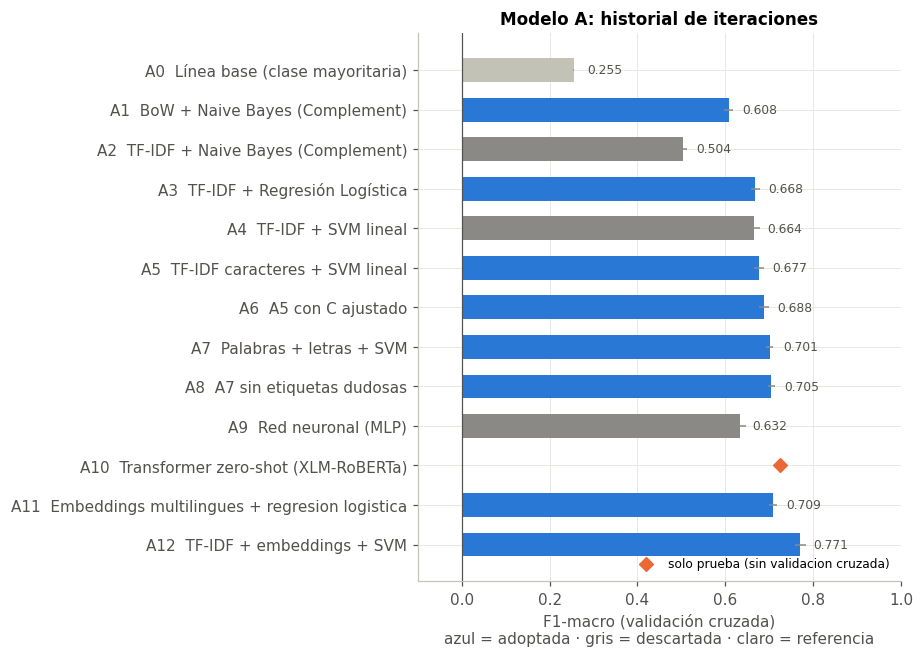

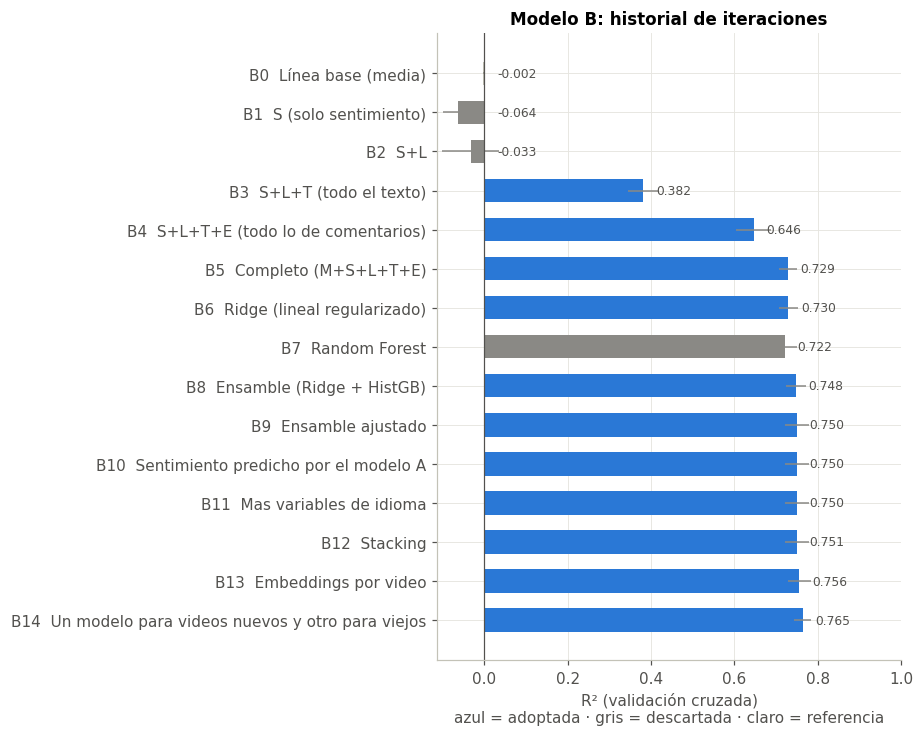

In [ ]:
tabla_reg = pd.DataFrame(registro)

def color_decision(d):
    if d.startswith("adoptada"):
        return AZUL
    if d.startswith("descartada"):
        return GRIS
    return "#c3c2b7"

def grafica_iteraciones(modelo, titulo, eje, nombre):
    t = tabla_reg[tabla_reg["modelo"] == modelo].copy()
    t["etiqueta"] = t["iteracion"] + "  " + t["descripcion"].str.slice(0, 52)
    t = t.iloc[::-1].reset_index(drop=True)
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(t) + 1.4))
    con_cv = t["cv_media"].notna().values
    ax.barh(y[con_cv], t["cv_media"][con_cv], xerr=t["cv_std"][con_cv].fillna(0),
            color=[color_decision(d) for d in t["decision"][con_cv]], height=0.6, error_kw=dict(ecolor=GRIS, lw=1))
    solo_test = (t["cv_media"].isna() & t["test"].notna()).values
    if solo_test.any():
        ax.scatter(t["test"][solo_test], y[solo_test], marker="D", s=40, color=NARANJA, zorder=3,
                   label="solo prueba (sin validacion cruzada)")
    omitidas = (t["cv_media"].isna() & t["test"].isna()).values
    for yy in y[omitidas]:
        ax.text(0.01, yy, "omitida en este entorno", va="center", fontsize=8, color=TINTA2)
    for yy, val in zip(y, t["cv_media"]):
        if pd.notna(val):
            ax.text(max(val, 0) + 0.03, yy, f"{val:.3f}", va="center", fontsize=8, color=TINTA2)
    ax.set_yticks(y)
    ax.set_yticklabels(t["etiqueta"])
    ax.axvline(0, color=TINTA2, lw=0.8)
    ax.set_xlim(min(-0.1, t["cv_media"].min() - 0.05), 1)
    ax.set_xlabel(eje + "\nazul = adoptada · gris = descartada · claro = referencia")
    ax.set_title(titulo)
    if solo_test.any():
        ax.legend(frameon=False, loc="lower right", fontsize=8)
    guardar_fig(nombre)

grafica_iteraciones("A", "Modelo A: historial de iteraciones", "F1-macro (validación cruzada)", "fig12_iteraciones_A")
grafica_iteraciones("B", "Modelo B: historial de iteraciones", "R² (validación cruzada)", "fig13_iteraciones_B")

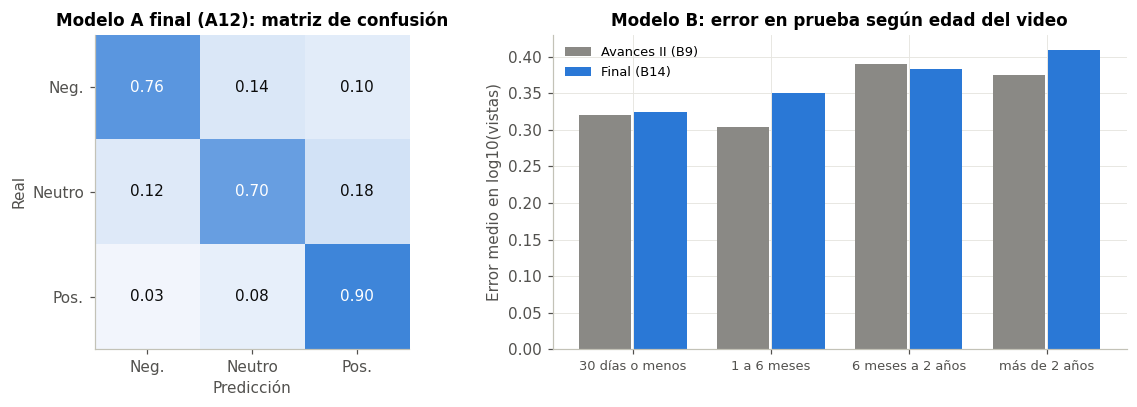

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.1]})
cm_final = confusion_matrix(yte, final_A["pred"], normalize="true")
axes[0].imshow(cm_final, cmap=LinearSegmentedColormap.from_list("seq", ["#f7f9fd", AZUL]), vmin=0, vmax=1)
etq = ["Neg.", "Neutro", "Pos."]
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(etq)
axes[0].set_yticks(range(3))
axes[0].set_yticklabels(etq)
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Real")
axes[0].grid(False)
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{cm_final[i, j]:.2f}", ha="center", va="center",
                     color="white" if cm_final[i, j] > 0.5 else TINTA)
axes[0].set_title(f"Modelo A final ({final_A['id']}): matriz de confusión")

x = np.arange(len(por_edad))
axes[1].bar(x - 0.2, por_edad["mae_B9"], width=0.38, color=GRIS, label="Avances II (B9)")
axes[1].bar(x + 0.2, por_edad["mae"], width=0.38, color=AZUL, label=f"Final ({final_B['id']})")
axes[1].set_xticks(x)
axes[1].set_xticklabels(por_edad.index.astype(str), fontsize=8.5)
axes[1].set_ylabel("Error medio en log10(vistas)")
axes[1].set_title("Modelo B: error en prueba según edad del video")
axes[1].legend(frameon=False, fontsize=8.5)
guardar_fig("fig14_finales_y_errores")

### 9.7 Guardar y descargar resultados
Se guarda el registro de iteraciones, las metricas nuevas y los modelos finales. Al final se crea un zip con las
figuras y los resultados (sin los modelos, que pesan mucho) y se descarga solo

In [ ]:
cols_reg = ["modelo", "iteracion", "etapa", "descripcion", "cambio", "motivo", "herramienta", "metrica",
            "cv_media", "cv_std", "test", "p_valor", "mae_test", "segundos", "decision"]
tabla_reg = pd.DataFrame(registro).reindex(columns=cols_reg)
tabla_reg.to_csv(OUT_DIR / "registro_iteraciones.csv", index=False, encoding="utf-8")
registrar("avances3_herramientas", {"transformers": HAY_TRANSFORMERS, "sentence_transformers": HAY_SBERT,
                                     "dispositivo": DISPOSITIVO, "mlflow": mlflow is not None,
                                     "n_iteraciones_A": int((tabla_reg["modelo"] == "A").sum()),
                                     "n_iteraciones_B": int((tabla_reg["modelo"] == "B").sum())})
nuevas = {k: v for k, v in RESULTADOS.items() if k.startswith("avances3_")}
with open(OUT_DIR / "metricas_avances3.json", "w", encoding="utf-8") as f:
    json.dump(nuevas, f, ensure_ascii=False, indent=2)
with open(OUT_DIR / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=2)
for nombre_archivo, modelo_final in [("modelo_sentimiento_v3.joblib", final_A["modelo"]),
                                     ("modelo_desempeno_v3.joblib", final_B["modelo"])]:
    try:
        joblib.dump(modelo_final, OUT_DIR / nombre_archivo)
    except Exception as e:
        print("No se pudo guardar", nombre_archivo, ":", e)

if mlflow is not None:
    try:
        corridas = mlflow.search_runs(experiment_names=["proyecto_youtube_avances3"])
        print("Iteraciones guardadas en MLflow:", len(corridas))
    except Exception as e:
        print("No se pudieron leer las corridas de MLflow:", e)

ruta_zip = Path("resultados_avances3.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in sorted(FIG_DIR.glob("*.png")):
        z.write(archivo)
    for archivo in sorted(OUT_DIR.glob("*")):
        if archivo.suffix in (".csv", ".json", ".db"):
            z.write(archivo)
print("Zip creado:", ruta_zip.resolve(), f"({ruta_zip.stat().st_size / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(str(ruta_zip))
except Exception:
    print("No se esta en Colab, el zip queda en la carpeta del notebook")

tabla_reg[["iteracion", "descripcion", "cv_media", "test", "decision"]]

Iteraciones guardadas en MLflow: 28
Zip creado: /content/resultados_avances3.zip (1.9 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,iteracion,descripcion,cv_media,test,decision
0,A0,Línea base (clase mayoritaria),0.254600,NaN,referencia
1,A1,BoW + Naive Bayes (Complement),0.608000,NaN,adoptada
2,A2,TF-IDF + Naive Bayes (Complement),0.504000,NaN,descartada
3,A3,TF-IDF + Regresión Logística,0.668000,NaN,adoptada
4,A4,TF-IDF + SVM lineal,0.664400,NaN,descartada
5,A5,TF-IDF caracteres + SVM lineal,0.676600,NaN,adoptada
6,A6,A5 con C ajustado,0.687769,0.690000,adoptada (modelo final de Avances II)
7,B0,Línea base (media),-0.002200,NaN,referencia
8,B1,S (solo sentimiento),-0.063600,NaN,descartada
9,B2,S+L,-0.032600,NaN,descartada
